In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 8192     # Increased batch size for better training stability
EPOCHS = 200          # More epochs for better convergence
LOG_INTERVAL = 50     # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
LATENT_DIM = 256
HIDDEN_DIM = 4096
COUPLING_HIDDEN_DIM = 512
N_COUPLE_LAYERS = 8

# VAE-specific hyperparameters
LR = 5e-4             # Lower learning rate for more stable training
BETA = 0.5            # Reduced beta to prevent posterior collapse
BETA_WARMUP = 50      # Epochs to gradually increase beta
WEIGHT_DECAY = 1e-5   # L2 regularization

# Visualization settings
SAVE_PLT_INTERVAL = 10  # How often to save plots (every 10 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE} (increased for stability)")
print(f"Epochs: {EPOCHS} (more epochs for convergence)")
print(f"Hidden dimension: {HIDDEN_DIM} (larger capacity)")
print(f"Latent dimension: {LATENT_DIM} (increased for better representation)")
print(f"Learning rate: {LR} (lower for stability)")
print(f"Beta (KL weight): {BETA} (reduced to prevent collapse)")
print(f"Beta warmup epochs: {BETA_WARMUP}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Device: {device}")


Batch size: 8192 (increased for stability)
Epochs: 200 (more epochs for convergence)
Hidden dimension: 4096 (larger capacity)
Latent dimension: 256 (increased for better representation)
Learning rate: 0.0005 (lower for stability)
Beta (KL weight): 0.5 (reduced to prevent collapse)
Beta warmup epochs: 50
Weight decay: 1e-05
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.Compose([torchvision.transforms.ToTensor(), torch.flatten])
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")


Batch size: 8192
Training batches: 8
Test batches: 2


In [5]:
class CouplingLayer(nn.Module):
    """
    A coupling layer that transforms data using neural networks.

    The key idea:
    - Split input x into two parts using a mask
    - Transform one part based on the other part
    - Combine them back together
    """

    def __init__(self, input_dim, output_dim, hid_dim, mask):
        super().__init__()

        # The mask determines which dimensions to transform
        # mask = [0, 1] means: don't transform dimension 0, transform dimension 1
        self.register_buffer("mask", mask, persistent=False)

        # Neural networks to compute scaling (s) and translation (t) factors
        # These networks take the "untransformed" part and predict how to transform the other part

        # Scaling network (s): predicts how much to scale each dimension
        self.s_fc1 = nn.Linear(input_dim, hid_dim)
        self.s_fc2 = nn.Linear(hid_dim, hid_dim)
        self.s_fc3 = nn.Linear(hid_dim, hid_dim)
        self.s_fc4 = nn.Linear(hid_dim, output_dim)

        # Translation network (t): predicts how much to shift each dimension
        self.t_fc1 = nn.Linear(input_dim, hid_dim)
        self.t_fc2 = nn.Linear(hid_dim, hid_dim)
        self.t_fc3 = nn.Linear(hid_dim, hid_dim)
        self.t_fc4 = nn.Linear(hid_dim, output_dim)

    def forward(self, x):
        """
        Transform x to y using the coupling layer.
        Returns: y (transformed data) and log_det_jacobian (for computing likelihood)
        """
        # Apply mask to get the "untransformed" part
        x_m = x * self.mask

        # Compute scaling and translation factors from the untransformed part
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(x_m))))))))
        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(x_m)))))))

        # Apply the transformation: y = x_m + (1-mask) * (x * exp(s) + t)
        # This means: keep the masked part unchanged, transform the unmasked part
        y = x_m + (1 - self.mask) * (x * torch.exp(s_out) + t_out)

        # Compute log determinant of Jacobian (needed for likelihood computation)
        log_det_jacobian = s_out.sum(dim=1)

        return y, log_det_jacobian

    def backward(self, y):
        """
        Reverse transformation: convert y back to x.
        This is what makes the flow invertible!
        """
        # Apply mask to get the "untransformed" part
        y_m = y * self.mask

        # Compute scaling and translation factors
        s_out = torch.tanh(self.s_fc4(F.relu(self.s_fc3(F.relu(self.s_fc2(F.relu(self.s_fc1(y_m))))))))

        t_out = self.t_fc4(F.relu(self.t_fc3(F.relu(self.t_fc2(F.relu(self.t_fc1(y_m)))))))

        # Reverse the transformation: x = y_m + (1-mask) * (y - t) * exp(-s)
        x = y_m + (1 - self.mask) * (y - t_out) * torch.exp(-s_out)

        return x


In [6]:
class VAE(nn.Module):
    """
    Variational Autoencoder with better architecture and training stability.
    """
    
    def __init__(self, input_dim, latent_dim, hidden_dim, coupling_hid_dim, mask, n_layers=6):
        super().__init__()
        
        self.input_dim = input_dim
        self.latent_dim = latent_dim
        self.hidden_dim = hidden_dim

        self.coupling_layers = nn.ModuleList()

        # First layer uses the given mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Middle layers alternate the mask pattern
        # This ensures all dimensions get transformed
        for _ in range(n_layers - 2):
            mask = 1 - mask  # Flip the mask
            self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, mask))

        # Last layer uses the opposite mask
        self.coupling_layers.append(CouplingLayer(latent_dim, latent_dim, coupling_hid_dim, 1 - mask))
        
        # Encoder network with batch normalization and dropout
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),

            nn.Linear(hidden_dim // 2, latent_dim),
        )
        
        # Encoder outputs (mean and log variance)
        self.fc_mu = nn.Linear(latent_dim, latent_dim)
        self.fc_logvar = nn.Linear(latent_dim, latent_dim)
        
        # Decoder network with batch normalization and dropout
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, latent_dim),

            nn.Linear(latent_dim, hidden_dim // 2),
            nn.BatchNorm1d(hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim // 2, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.1),
            
            nn.Linear(hidden_dim, input_dim),
        )
        
        # Initialize weights properly
        self._initialize_weights()
    
    def _initialize_weights(self):
        """Initialize network weights for better training."""
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.constant_(m.bias, 0)
            elif isinstance(m, nn.BatchNorm1d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)
    
    def encode(self, x):
        """
        Encode input data into latent space.
        
        Args:
            x: Input data tensor of shape (batch_size, input_dim)
        
        Returns:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        x = self.encoder(x)

        for coupling_layer in self.coupling_layers:
            x, _ = coupling_layer(x)

        mu = self.fc_mu(x)
        logvar = self.fc_logvar(x)
        # Clamp logvar to prevent numerical instability
        logvar = torch.clamp(logvar, min=-10, max=10)
        return mu, logvar
    
    def reparameterize(self, mu, logvar):
        """
        Reparameterization trick for sampling from latent distribution.
        
        Args:
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        
        Returns:
            z: Sampled latent vector
        """
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std
    
    def decode(self, z):
        """
        Decode latent vector back to data space.
        
        Args:
            z: Latent vector of shape (batch_size, latent_dim)
        
        Returns:
            reconstructed: Reconstructed data
        """

        for coupling_layer in reversed(self.coupling_layers):
            z = coupling_layer.backward(z)

        return self.decoder(z)
    
    def forward(self, x):
        """
        Forward pass through the VAE.
        
        Args:
            x: Input data tensor
        
        Returns:
            reconstructed: Reconstructed data
            mu: Mean of latent distribution
            logvar: Log variance of latent distribution
        """
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        reconstructed = self.decode(z)
        return reconstructed, mu, logvar


In [7]:
mask = torch.from_numpy(np.concat([np.zeros(LATENT_DIM // 2), np.ones(LATENT_DIM // 2)]).astype(np.float32))

# Initialize model
vae = VAE(INPUT_DIM, LATENT_DIM, HIDDEN_DIM, COUPLING_HIDDEN_DIM, mask, N_COUPLE_LAYERS)

# Move model to device
vae = vae.to(device)

# Set up optimizer with weight decay
optimizer = torch.optim.Adam(vae.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate scheduler for better convergence
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=20
)

print(f"Model parameters: {sum(p.numel() for p in vae.parameters()):,}")
print(f"Learning rate: {LR}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Model moved to device: {device}")
print(f"Learning rate scheduler: ReduceLROnPlateau")

# Let's see what our model looks like
print("\nVAE architecture:")
print(vae)


Model parameters: 70,674,192
Learning rate: 0.0005
Weight decay: 1e-05
Model moved to device: cuda
Learning rate scheduler: ReduceLROnPlateau

VAE architecture:
VAE(
  (coupling_layers): ModuleList(
    (0-7): 8 x CouplingLayer(
      (s_fc1): Linear(in_features=256, out_features=512, bias=True)
      (s_fc2): Linear(in_features=512, out_features=512, bias=True)
      (s_fc3): Linear(in_features=512, out_features=512, bias=True)
      (s_fc4): Linear(in_features=512, out_features=256, bias=True)
      (t_fc1): Linear(in_features=256, out_features=512, bias=True)
      (t_fc2): Linear(in_features=512, out_features=512, bias=True)
      (t_fc3): Linear(in_features=512, out_features=512, bias=True)
      (t_fc4): Linear(in_features=512, out_features=256, bias=True)
    )
  )
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=4096, bias=True)
    (1): BatchNorm1d(4096, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dr

In [8]:
def vae_loss(reconstructed, original, mu, logvar, beta=1.0):
    """
    Compute the VAE loss function with better numerical stability.
    
    Args:
        reconstructed: Reconstructed data from decoder
        original: Original input data
        mu: Mean of latent distribution
        logvar: Log variance of latent distribution
        beta: Weight for KL divergence term
    
    Returns:
        total_loss: Total VAE loss
        recon_loss: Reconstruction loss
        kl_loss: KL divergence loss
    """
    # Reconstruction loss (MSE with mean reduction for better scaling)
    recon_loss = F.mse_loss(reconstructed, original, reduction='mean')
    
    # KL divergence loss with numerical stability
    # KL(q(z|x) || p(z)) where p(z) = N(0, I)
    # closed form analytical solution for KL divergence
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    
    # Total loss
    total_loss = recon_loss + beta * kl_loss
    
    return total_loss, recon_loss, kl_loss

def get_beta_schedule(epoch, max_epochs, warmup_epochs):
    """
    Get beta value with warmup schedule to prevent posterior collapse.
    
    Args:
        epoch: Current epoch
        max_epochs: Total number of epochs
        warmup_epochs: Number of epochs for warmup
    
    Returns:
        beta: Current beta value
    """
    if epoch < warmup_epochs:
        # Linear warmup from 0 to BETA
        return BETA * (epoch / warmup_epochs)
    else:
        # Cyclical annealing to prevent posterior collapse
        cycle_length = 50
        cycle_position = (epoch - warmup_epochs) % cycle_length
        cycle_progress = cycle_position / cycle_length
        return BETA * (0.5 + 0.5 * np.cos(np.pi * cycle_progress))

def train_epoch(epoch):
    """
    Train the VAE for one epoch with beta scheduling.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_total_loss: Average total loss for this epoch
        avg_recon_loss: Average reconstruction loss
        avg_kl_loss: Average KL divergence loss
        current_beta: Current beta value used
    """
    vae.train()
    
    # Get current beta value with scheduling
    current_beta = get_beta_schedule(epoch, EPOCHS, BETA_WARMUP)
    
    total_losses = []
    recon_losses = []
    kl_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        data = data.to(device)
        
        # Clear gradients
        optimizer.zero_grad()
        
        # Forward pass
        reconstructed, mu, logvar = vae(data)
        
        # Compute loss with current beta
        total_loss, recon_loss, kl_loss = vae_loss(reconstructed, data, mu, logvar, current_beta)
        
        # Backward pass
        total_loss.backward()
        
        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(vae.parameters(), max_norm=1.0)
        
        optimizer.step()
        
        # Track losses
        total_losses.append(total_loss.item())
        recon_losses.append(recon_loss.item())
        kl_losses.append(kl_loss.item())
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tTotal Loss: {:.6f}\tRecon Loss: {:.6f}\tKL Loss: {:.6f}\tBeta: {:.3f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), total_loss.item(), recon_loss.item(), kl_loss.item(), current_beta))
    
    # Calculate average losses
    avg_total_loss = sum(total_losses) / len(total_losses)
    avg_recon_loss = sum(recon_losses) / len(recon_losses)
    avg_kl_loss = sum(kl_losses) / len(kl_losses)
    
    # Update learning rate scheduler
    scheduler.step(avg_total_loss)
    
    print('====> Epoch: {} Average Total Loss: {:.4f}, Average Recon Loss: {:.4f}, Average KL Loss: {:.4f}, Beta: {:.3f}'.format(
        epoch, avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta))
    
    return avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta

In [9]:
def generate_samples(num_samples=1000):
    """
    Generate new samples using the VAE decoder.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        generated_samples: Generated data as numpy array
    """
    vae.eval()
    
    with torch.no_grad():
        # Sample from standard Gaussian in latent space
        z = torch.randn(num_samples, LATENT_DIM, device=device)
        
        # Decode to generate samples
        generated_samples = vae.decode(z)
        
        # Convert to numpy for visualization
        generated_samples = generated_samples.cpu().numpy()
    
    return generated_samples

def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

def visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=False):
    """
    Visualize the current state of our VAE training.
    
    Args:
        epoch: Current epoch number
        total_losses: List of total losses
        recon_losses: List of reconstruction losses
        kl_losses: List of KL divergence losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Loss plots
    if len(total_losses) > 0:
        epochs_range = range(1, len(total_losses) + 1)
        
        # Total loss
        plt.subplot(2, 3, 4)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Total Loss')
        plt.title('Total Loss Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Reconstruction and KL losses
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=2)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Loss Components')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, total_losses, 'g-', label='Total Loss', linewidth=2)
        plt.plot(epochs_range, recon_losses, 'b-', label='Reconstruction Loss', linewidth=1, alpha=0.7)
        plt.plot(epochs_range, kl_losses, 'r-', label='KL Divergence Loss', linewidth=1, alpha=0.7)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('All Losses Combined')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    # Save plot if requested
    if save_plot:
        if not os.path.exists('vae_results'):
            os.makedirs('vae_results')
        plt.savefig(f'vae_results/vae_progress_epoch_{epoch}.png', dpi=150, bbox_inches='tight')
        print(f"💾 Saved plot: vae_results/vae_progress_epoch_{epoch}.png")
    
    plt.show()


🎯 Starting VAE training...
📊 Initial state (before training):
💾 Saved plot: vae_results/vae_progress_epoch_0.png


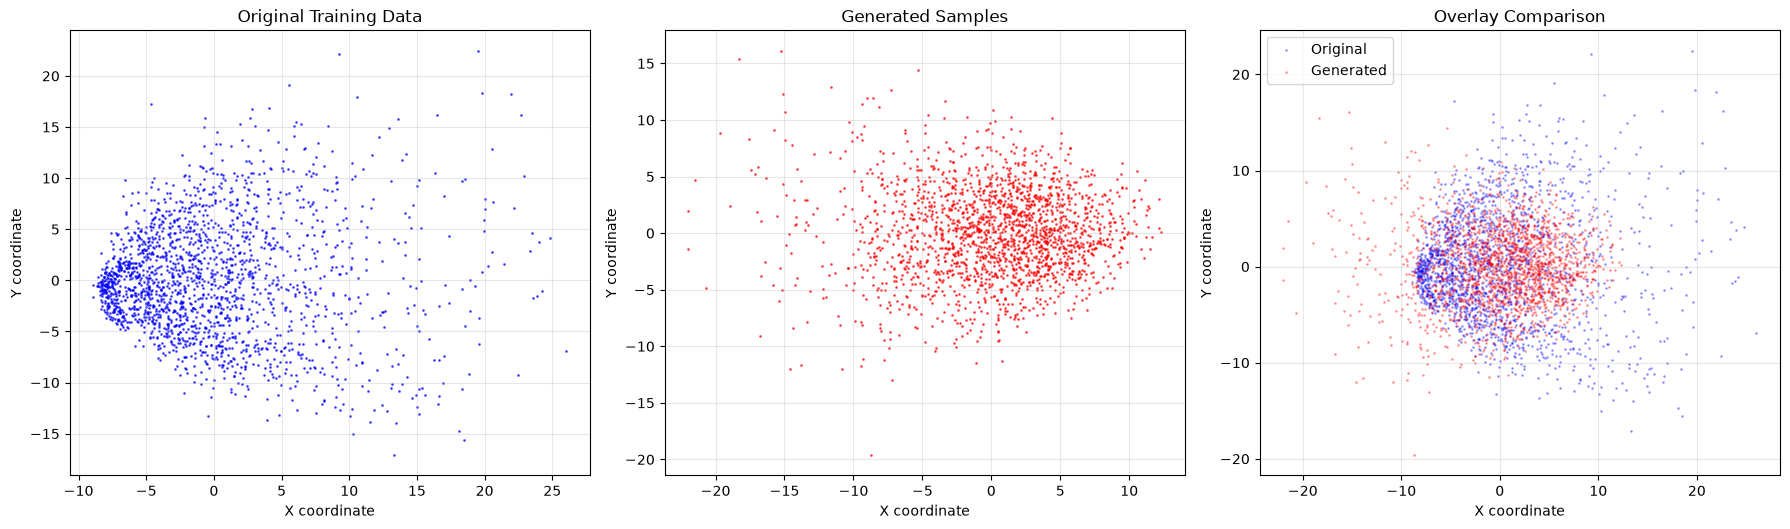


📊 Epoch 1/200
----------------------------------------
Epoch: 1 [0/60000 (0%)]	Total Loss: 1.087936	Recon Loss: 1.064322	KL Loss: 2.361345	Beta: 0.010
====> Epoch: 1 Average Total Loss: 8.4378, Average Recon Loss: 1.4405, Average KL Loss: 699.7296, Beta: 0.010
📈 Epoch 1 Summary:
   Total Loss: 8.4378
   Reconstruction Loss: 1.4405
   KL Divergence Loss: 699.7296
   Beta: 0.010
   Learning Rate: 0.000500

📊 Epoch 2/200
----------------------------------------
Epoch: 2 [0/60000 (0%)]	Total Loss: 31.209373	Recon Loss: 1.791865	KL Loss: 1470.875488	Beta: 0.020
====> Epoch: 2 Average Total Loss: 18.8714, Average Recon Loss: 1.4505, Average KL Loss: 871.0411, Beta: 0.020
📈 Epoch 2 Summary:
   Total Loss: 18.8714
   Reconstruction Loss: 1.4505
   KL Divergence Loss: 871.0411
   Beta: 0.020
   Learning Rate: 0.000500

📊 Epoch 3/200
----------------------------------------
Epoch: 3 [0/60000 (0%)]	Total Loss: 6.047307	Recon Loss: 0.599515	KL Loss: 181.593094	Beta: 0.030
====> Epoch: 3 Average T

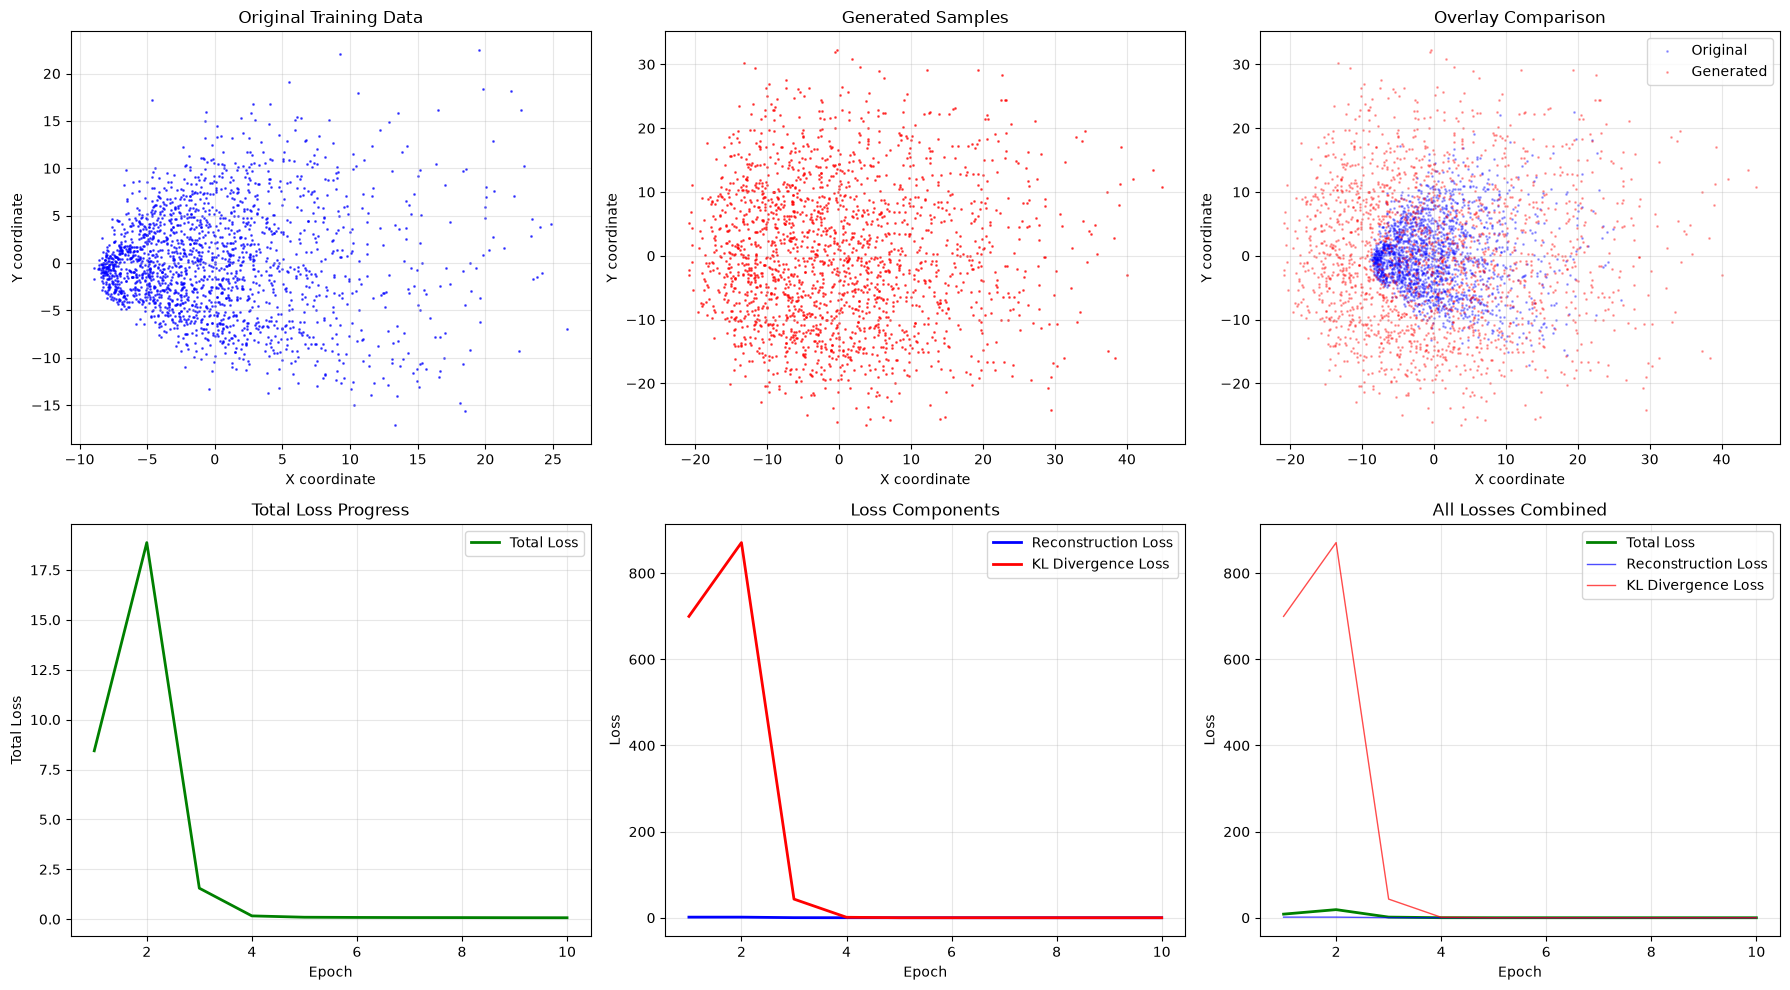

📈 Epoch 10 Summary:
   Total Loss: 0.0733
   Reconstruction Loss: 0.0676
   KL Divergence Loss: 0.0574
   Beta: 0.100
   Learning Rate: 0.000500

📊 Epoch 11/200
----------------------------------------
Epoch: 11 [0/60000 (0%)]	Total Loss: 0.072802	Recon Loss: 0.066461	KL Loss: 0.057644	Beta: 0.110
====> Epoch: 11 Average Total Loss: 0.0715, Average Recon Loss: 0.0654, Average KL Loss: 0.0556, Beta: 0.110
📈 Epoch 11 Summary:
   Total Loss: 0.0715
   Reconstruction Loss: 0.0654
   KL Divergence Loss: 0.0556
   Beta: 0.110
   Learning Rate: 0.000500

📊 Epoch 12/200
----------------------------------------
Epoch: 12 [0/60000 (0%)]	Total Loss: 0.072005	Recon Loss: 0.065525	KL Loss: 0.053997	Beta: 0.120
====> Epoch: 12 Average Total Loss: 0.0707, Average Recon Loss: 0.0643, Average KL Loss: 0.0536, Beta: 0.120
📈 Epoch 12 Summary:
   Total Loss: 0.0707
   Reconstruction Loss: 0.0643
   KL Divergence Loss: 0.0536
   Beta: 0.120
   Learning Rate: 0.000500

📊 Epoch 13/200
-----------------------

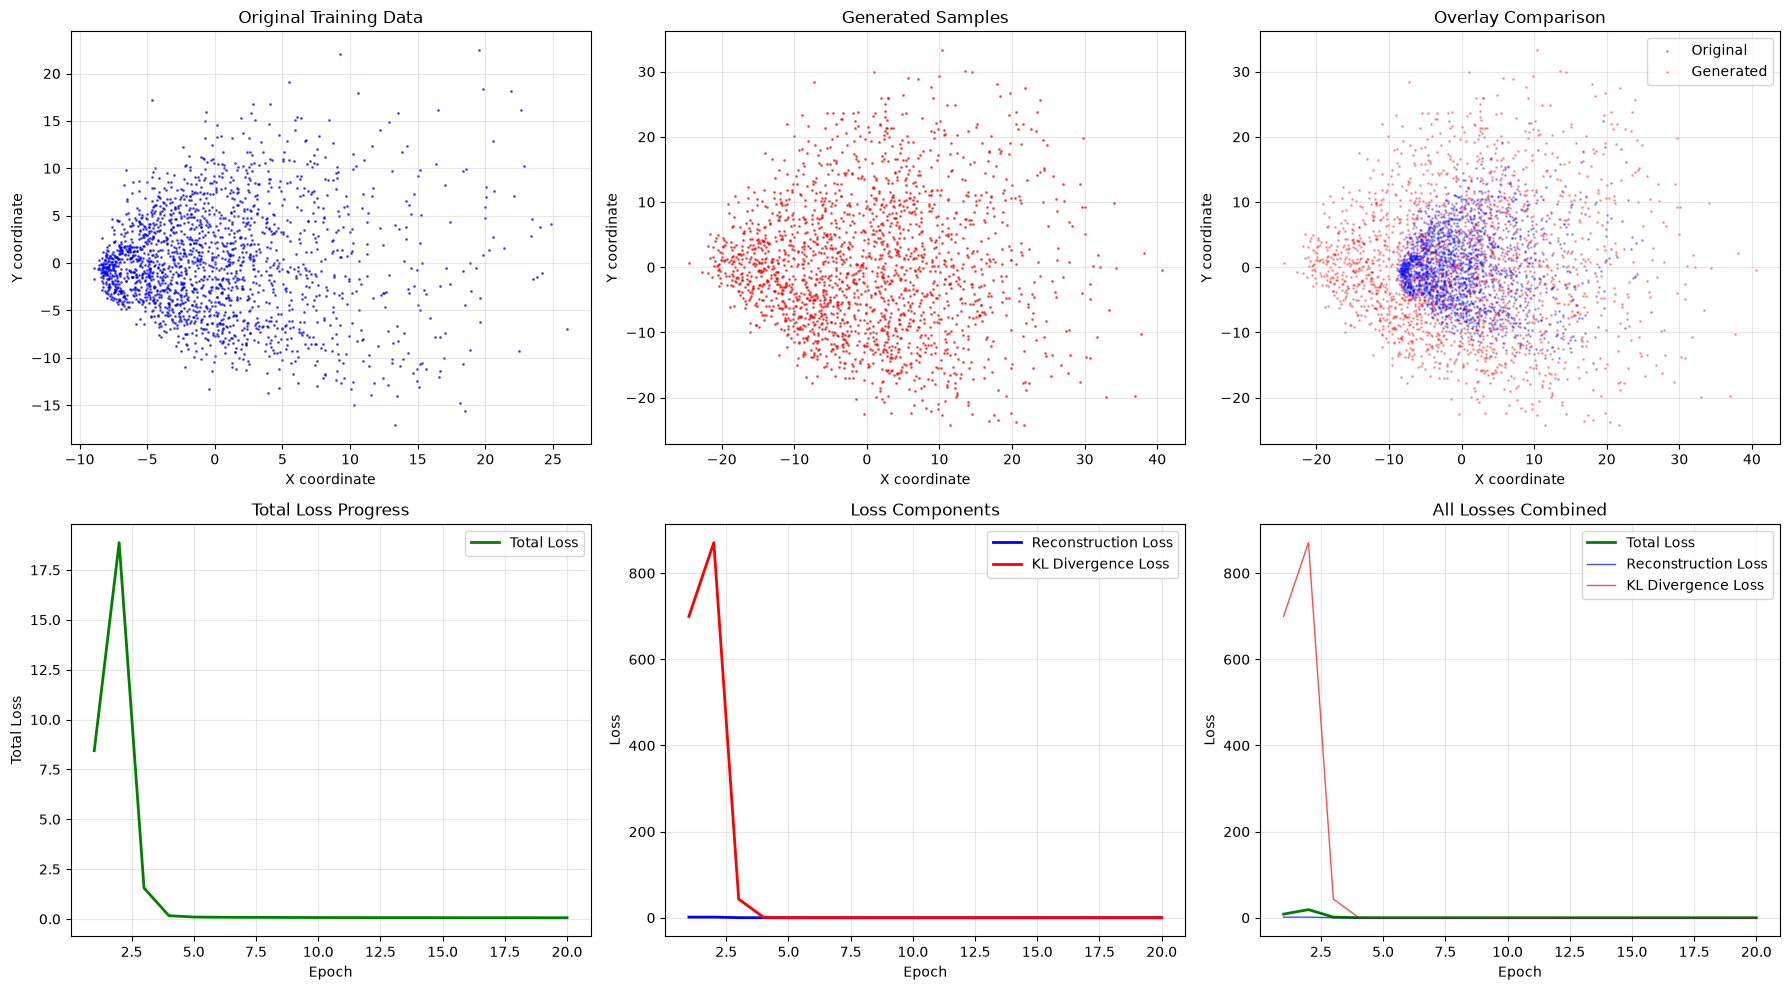

📈 Epoch 20 Summary:
   Total Loss: 0.0635
   Reconstruction Loss: 0.0552
   KL Divergence Loss: 0.0417
   Beta: 0.200
   Learning Rate: 0.000500

📊 Epoch 21/200
----------------------------------------
Epoch: 21 [0/60000 (0%)]	Total Loss: 0.062760	Recon Loss: 0.054463	KL Loss: 0.039509	Beta: 0.210
====> Epoch: 21 Average Total Loss: 0.0615, Average Recon Loss: 0.0530, Average KL Loss: 0.0403, Beta: 0.210
📈 Epoch 21 Summary:
   Total Loss: 0.0615
   Reconstruction Loss: 0.0530
   KL Divergence Loss: 0.0403
   Beta: 0.210
   Learning Rate: 0.000500

📊 Epoch 22/200
----------------------------------------
Epoch: 22 [0/60000 (0%)]	Total Loss: 0.062093	Recon Loss: 0.053306	KL Loss: 0.039942	Beta: 0.220
====> Epoch: 22 Average Total Loss: 0.0613, Average Recon Loss: 0.0529, Average KL Loss: 0.0383, Beta: 0.220
📈 Epoch 22 Summary:
   Total Loss: 0.0613
   Reconstruction Loss: 0.0529
   KL Divergence Loss: 0.0383
   Beta: 0.220
   Learning Rate: 0.000500

📊 Epoch 23/200
-----------------------

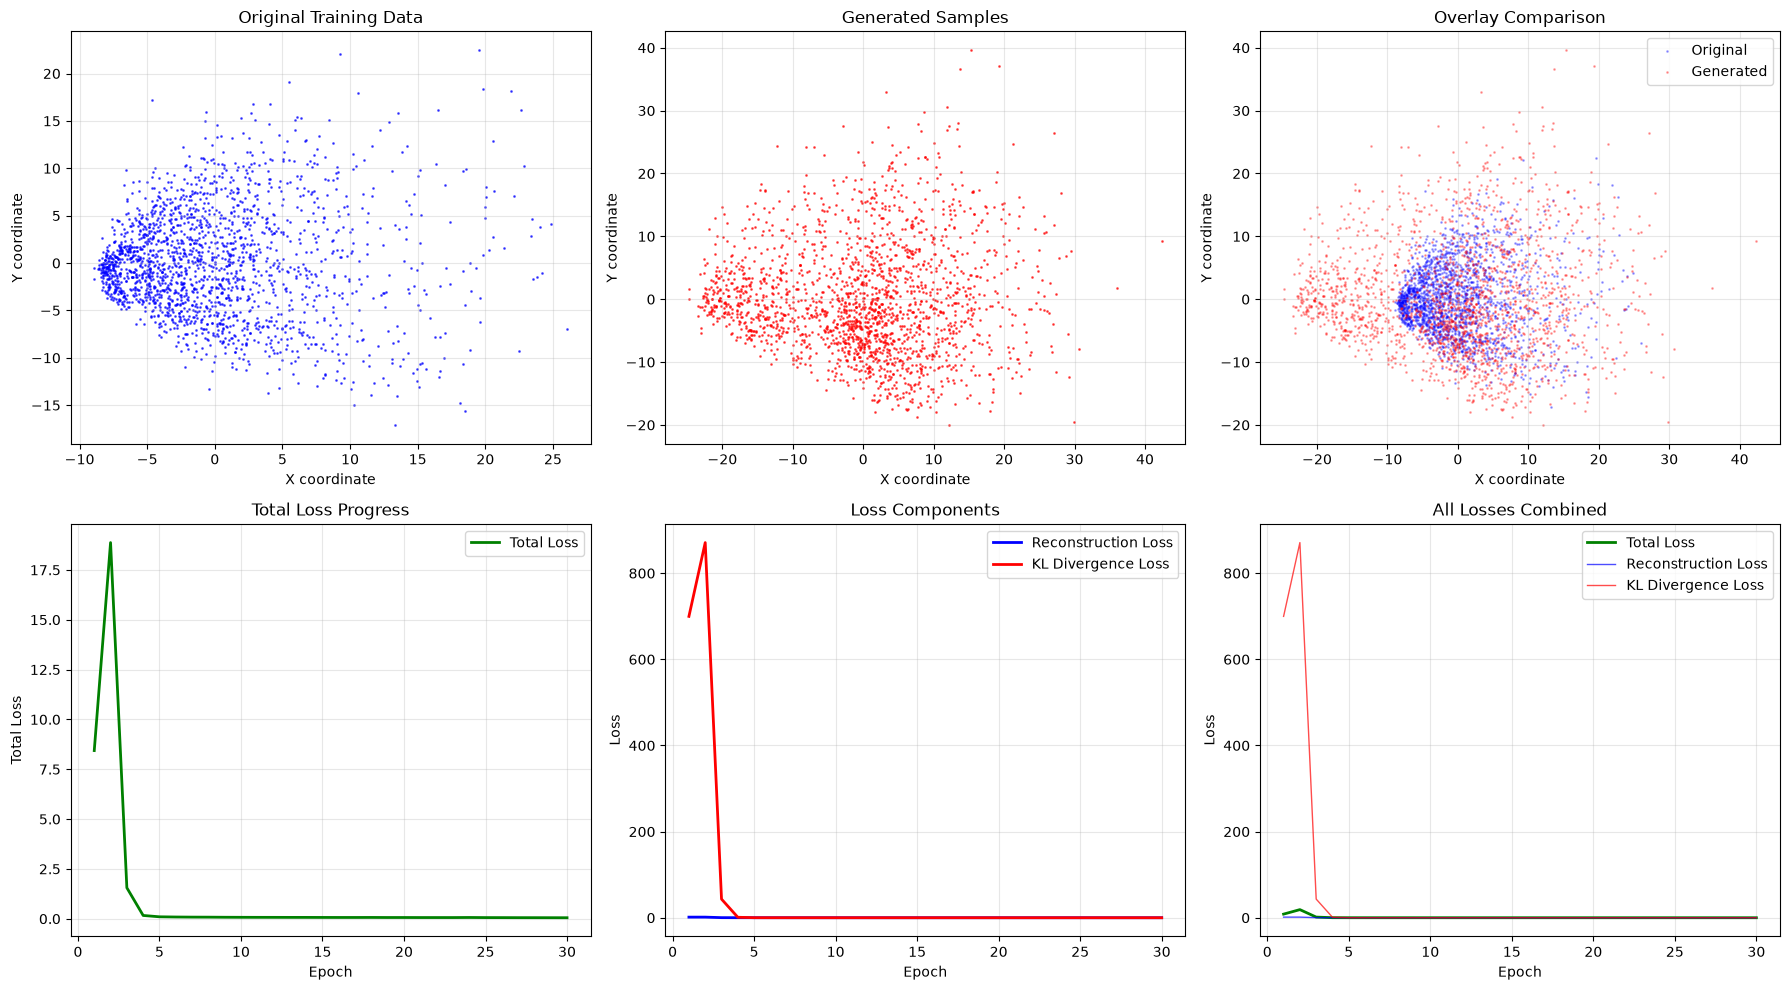

📈 Epoch 30 Summary:
   Total Loss: 0.0518
   Reconstruction Loss: 0.0419
   KL Divergence Loss: 0.0331
   Beta: 0.300
   Learning Rate: 0.000500

📊 Epoch 31/200
----------------------------------------
Epoch: 31 [0/60000 (0%)]	Total Loss: 0.051529	Recon Loss: 0.041351	KL Loss: 0.032832	Beta: 0.310
====> Epoch: 31 Average Total Loss: 0.0511, Average Recon Loss: 0.0410, Average KL Loss: 0.0327, Beta: 0.310
📈 Epoch 31 Summary:
   Total Loss: 0.0511
   Reconstruction Loss: 0.0410
   KL Divergence Loss: 0.0327
   Beta: 0.310
   Learning Rate: 0.000500

📊 Epoch 32/200
----------------------------------------
Epoch: 32 [0/60000 (0%)]	Total Loss: 0.050726	Recon Loss: 0.040368	KL Loss: 0.032367	Beta: 0.320
====> Epoch: 32 Average Total Loss: 0.0502, Average Recon Loss: 0.0399, Average KL Loss: 0.0323, Beta: 0.320
📈 Epoch 32 Summary:
   Total Loss: 0.0502
   Reconstruction Loss: 0.0399
   KL Divergence Loss: 0.0323
   Beta: 0.320
   Learning Rate: 0.000500

📊 Epoch 33/200
-----------------------

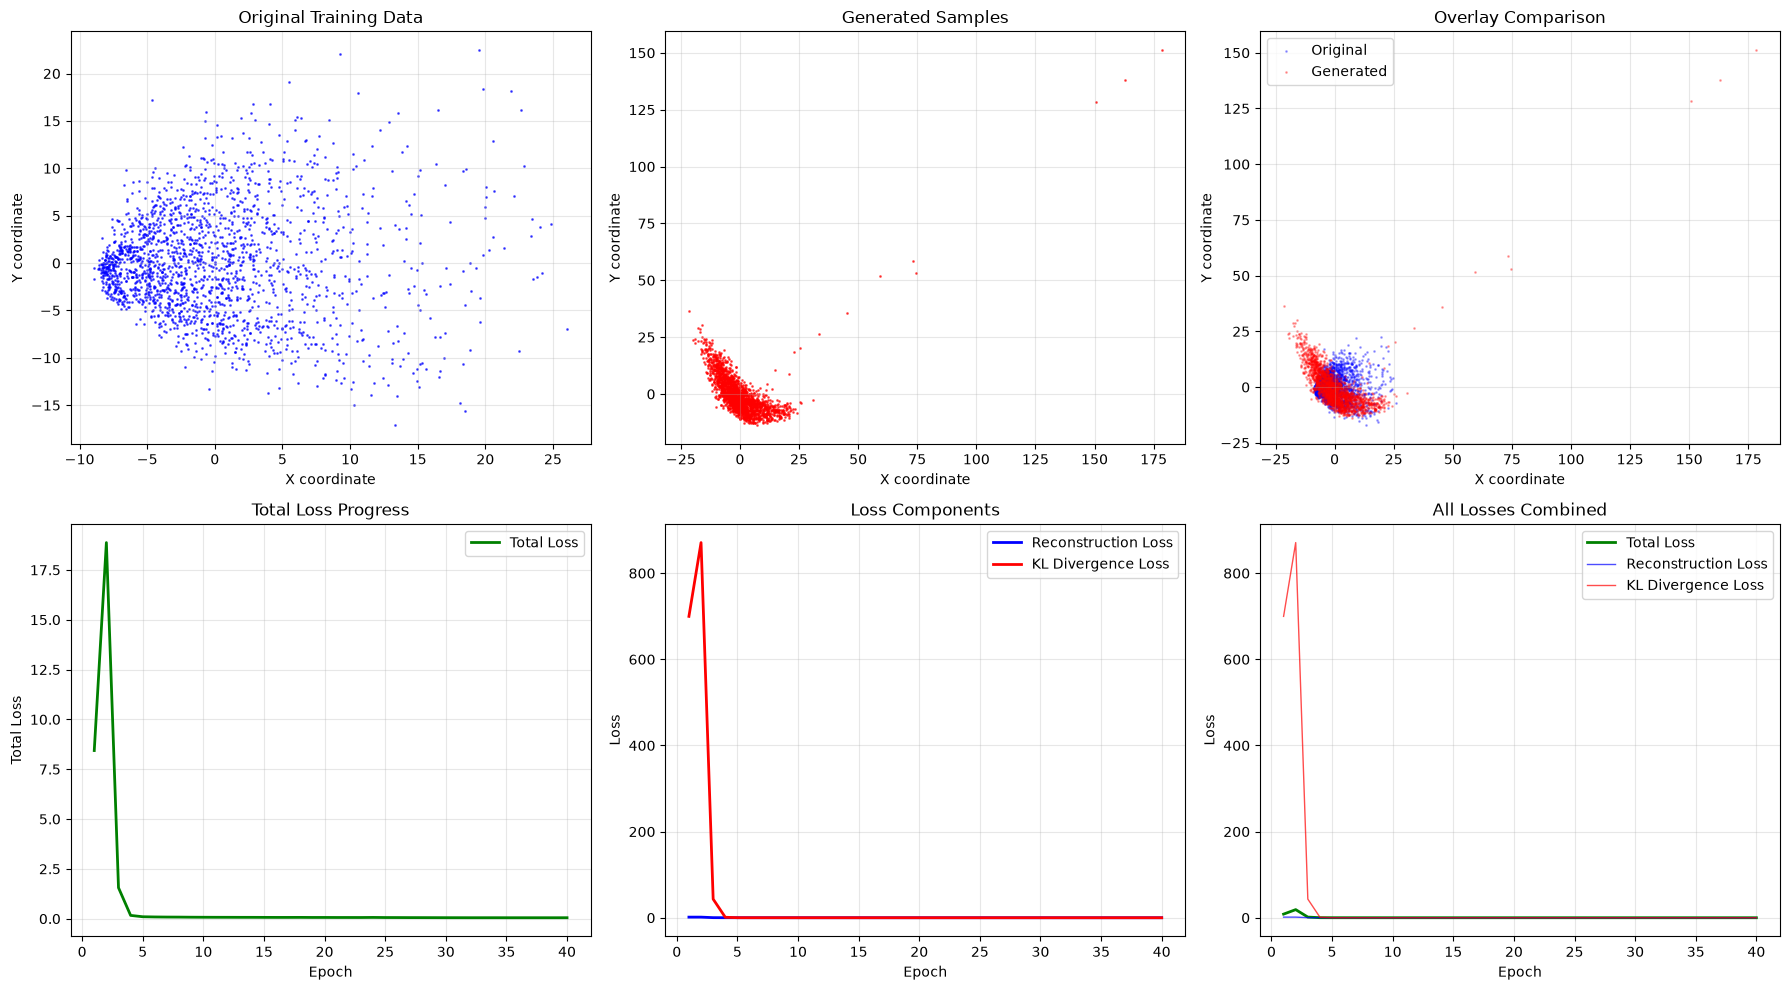

📈 Epoch 40 Summary:
   Total Loss: 0.0498
   Reconstruction Loss: 0.0380
   KL Divergence Loss: 0.0296
   Beta: 0.400
   Learning Rate: 0.000500

📊 Epoch 41/200
----------------------------------------
Epoch: 41 [0/60000 (0%)]	Total Loss: 0.068704	Recon Loss: 0.055005	KL Loss: 0.033411	Beta: 0.410
====> Epoch: 41 Average Total Loss: 0.1210, Average Recon Loss: 0.0838, Average KL Loss: 0.0908, Beta: 0.410
📈 Epoch 41 Summary:
   Total Loss: 0.1210
   Reconstruction Loss: 0.0838
   KL Divergence Loss: 0.0908
   Beta: 0.410
   Learning Rate: 0.000500

📊 Epoch 42/200
----------------------------------------
Epoch: 42 [0/60000 (0%)]	Total Loss: 0.115261	Recon Loss: 0.102887	KL Loss: 0.029462	Beta: 0.420
====> Epoch: 42 Average Total Loss: 0.0887, Average Recon Loss: 0.0755, Average KL Loss: 0.0316, Beta: 0.420
📈 Epoch 42 Summary:
   Total Loss: 0.0887
   Reconstruction Loss: 0.0755
   KL Divergence Loss: 0.0316
   Beta: 0.420
   Learning Rate: 0.000500

📊 Epoch 43/200
-----------------------

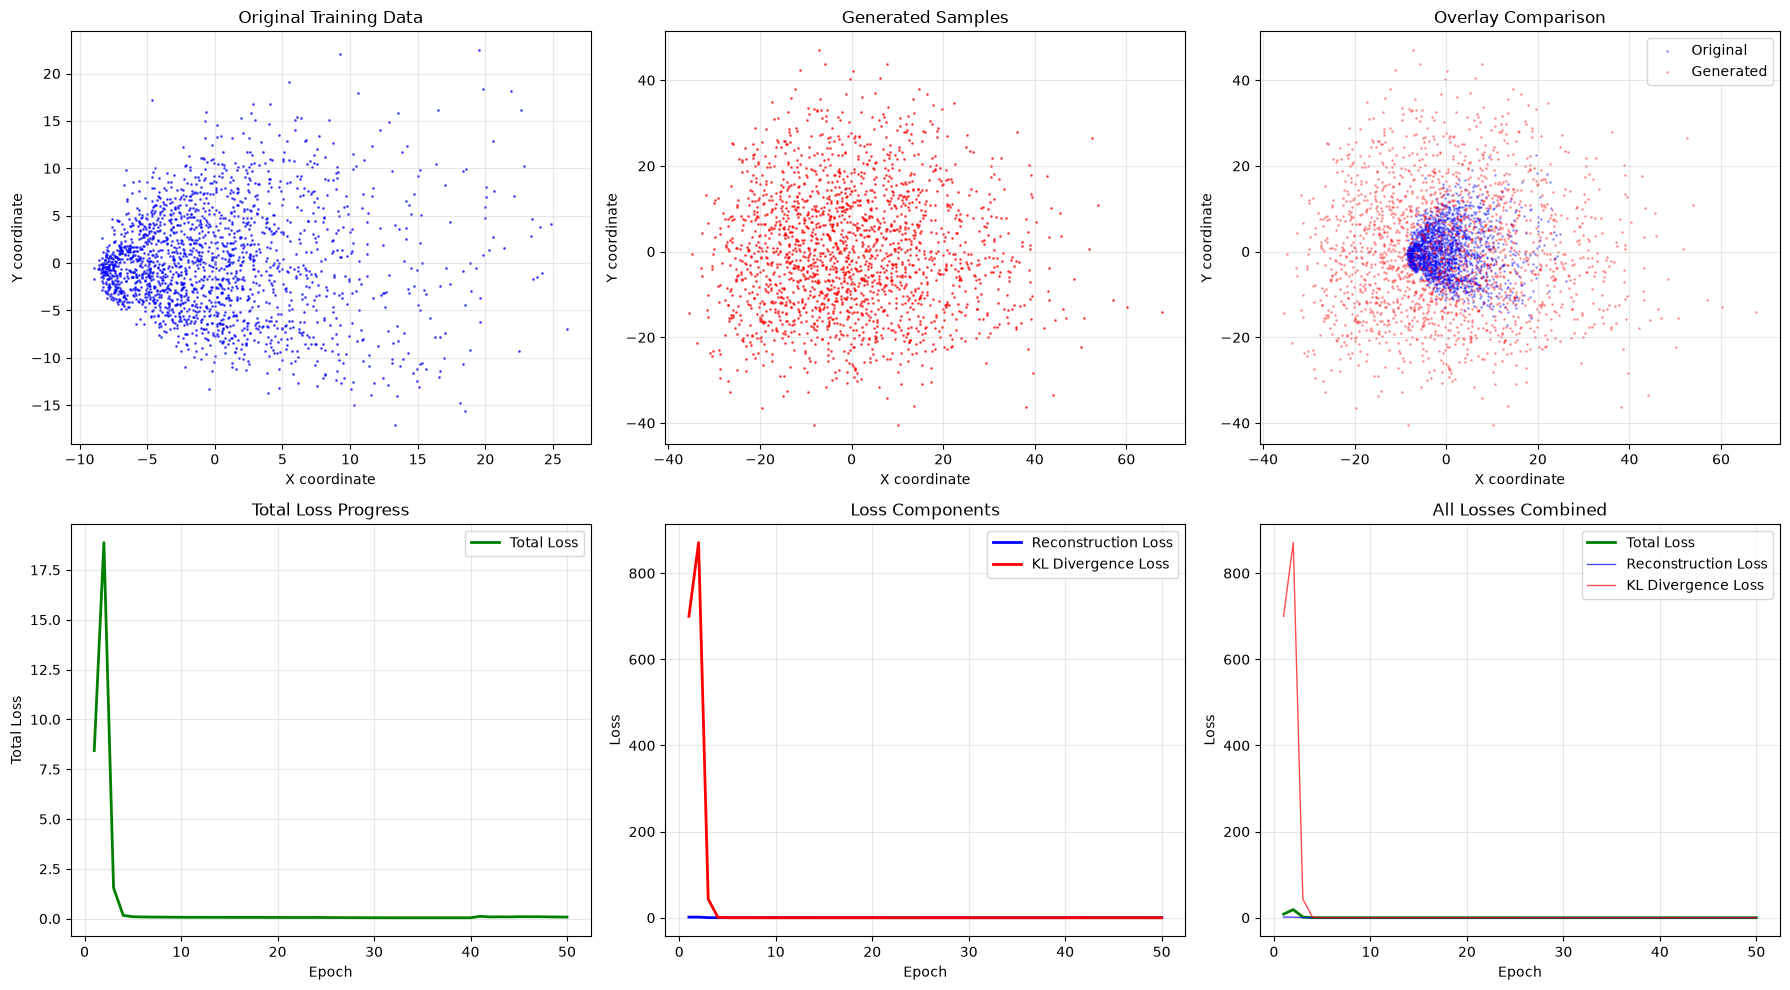

📈 Epoch 50 Summary:
   Total Loss: 0.0824
   Reconstruction Loss: 0.0786
   KL Divergence Loss: 0.0076
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 51/200
----------------------------------------
Epoch: 51 [0/60000 (0%)]	Total Loss: 0.081430	Recon Loss: 0.077222	KL Loss: 0.008424	Beta: 0.500
====> Epoch: 51 Average Total Loss: 0.0791, Average Recon Loss: 0.0744, Average KL Loss: 0.0094, Beta: 0.500
📈 Epoch 51 Summary:
   Total Loss: 0.0791
   Reconstruction Loss: 0.0744
   KL Divergence Loss: 0.0094
   Beta: 0.500
   Learning Rate: 0.000500

📊 Epoch 52/200
----------------------------------------
Epoch: 52 [0/60000 (0%)]	Total Loss: 0.078331	Recon Loss: 0.073270	KL Loss: 0.010162	Beta: 0.498
====> Epoch: 52 Average Total Loss: 0.0762, Average Recon Loss: 0.0710, Average KL Loss: 0.0106, Beta: 0.498
📈 Epoch 52 Summary:
   Total Loss: 0.0762
   Reconstruction Loss: 0.0710
   KL Divergence Loss: 0.0106
   Beta: 0.498
   Learning Rate: 0.000500

📊 Epoch 53/200
-----------------------

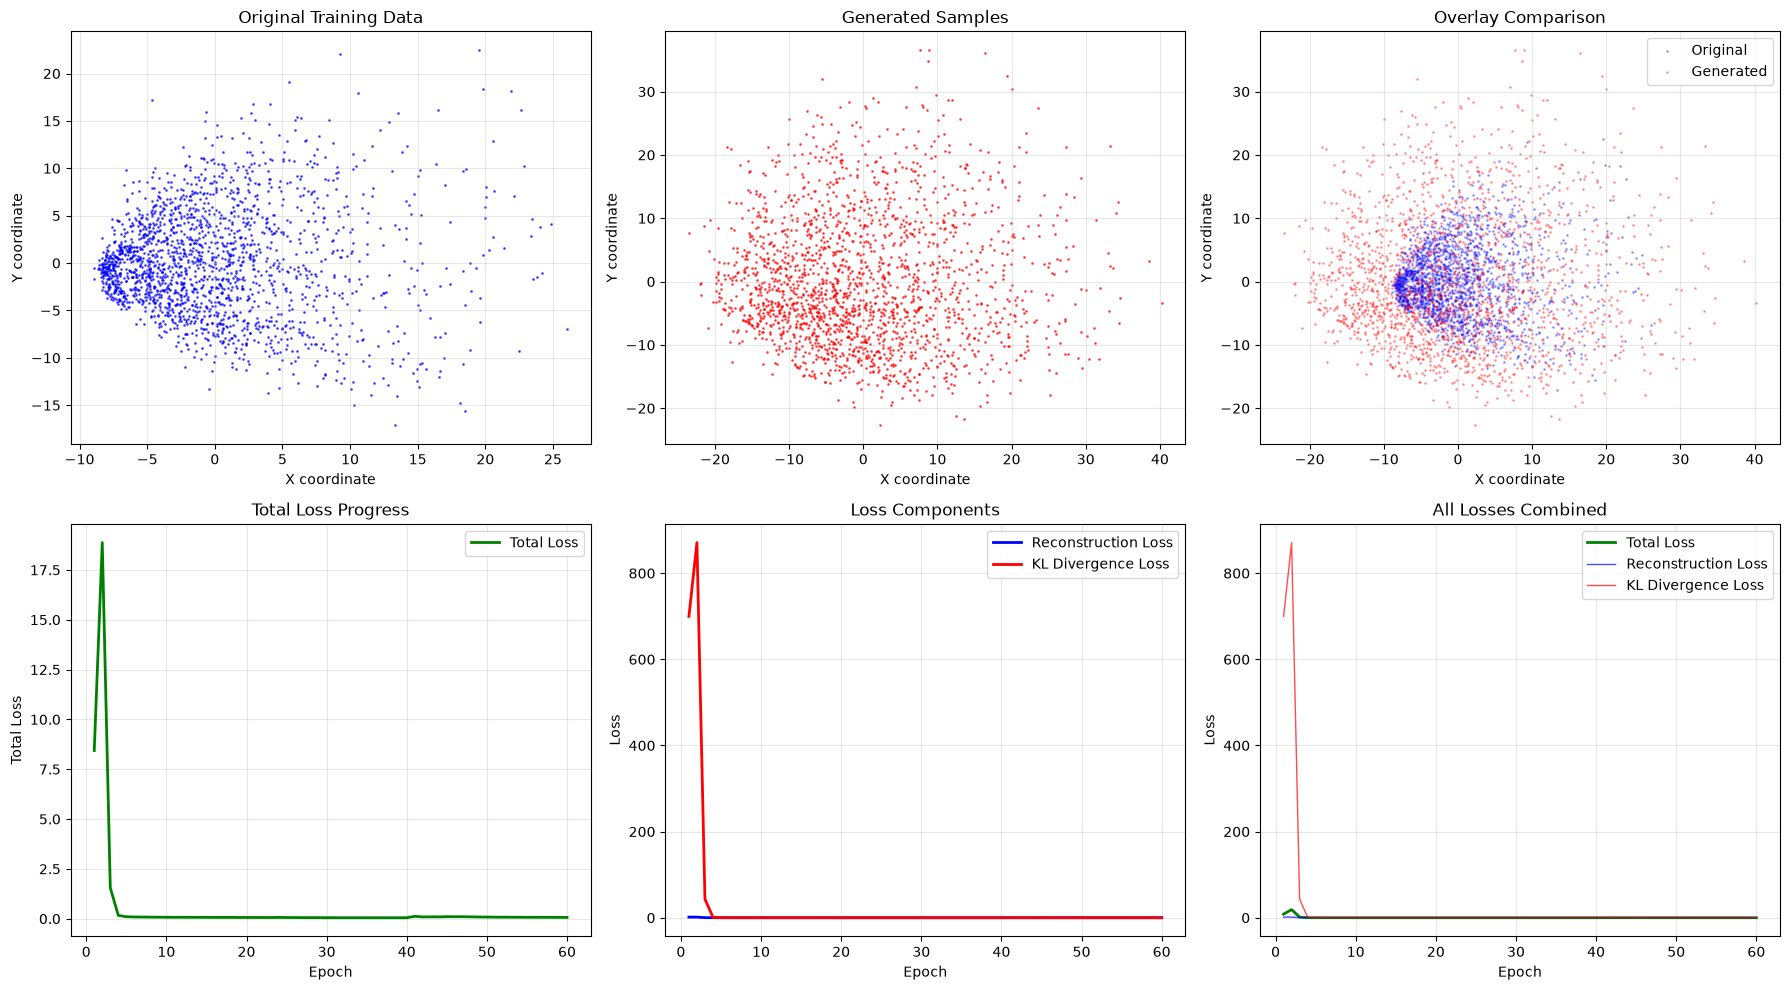

📈 Epoch 60 Summary:
   Total Loss: 0.0656
   Reconstruction Loss: 0.0573
   KL Divergence Loss: 0.0185
   Beta: 0.452
   Learning Rate: 0.000250

📊 Epoch 61/200
----------------------------------------
Epoch: 61 [0/60000 (0%)]	Total Loss: 0.064412	Recon Loss: 0.056013	KL Loss: 0.018976	Beta: 0.443
====> Epoch: 61 Average Total Loss: 0.0632, Average Recon Loss: 0.0547, Average KL Loss: 0.0193, Beta: 0.443
📈 Epoch 61 Summary:
   Total Loss: 0.0632
   Reconstruction Loss: 0.0547
   KL Divergence Loss: 0.0193
   Beta: 0.443
   Learning Rate: 0.000250

📊 Epoch 62/200
----------------------------------------
Epoch: 62 [0/60000 (0%)]	Total Loss: 0.062652	Recon Loss: 0.054185	KL Loss: 0.019587	Beta: 0.432
====> Epoch: 62 Average Total Loss: 0.0624, Average Recon Loss: 0.0538, Average KL Loss: 0.0198, Beta: 0.432
📈 Epoch 62 Summary:
   Total Loss: 0.0624
   Reconstruction Loss: 0.0538
   KL Divergence Loss: 0.0198
   Beta: 0.432
   Learning Rate: 0.000250

📊 Epoch 63/200
-----------------------

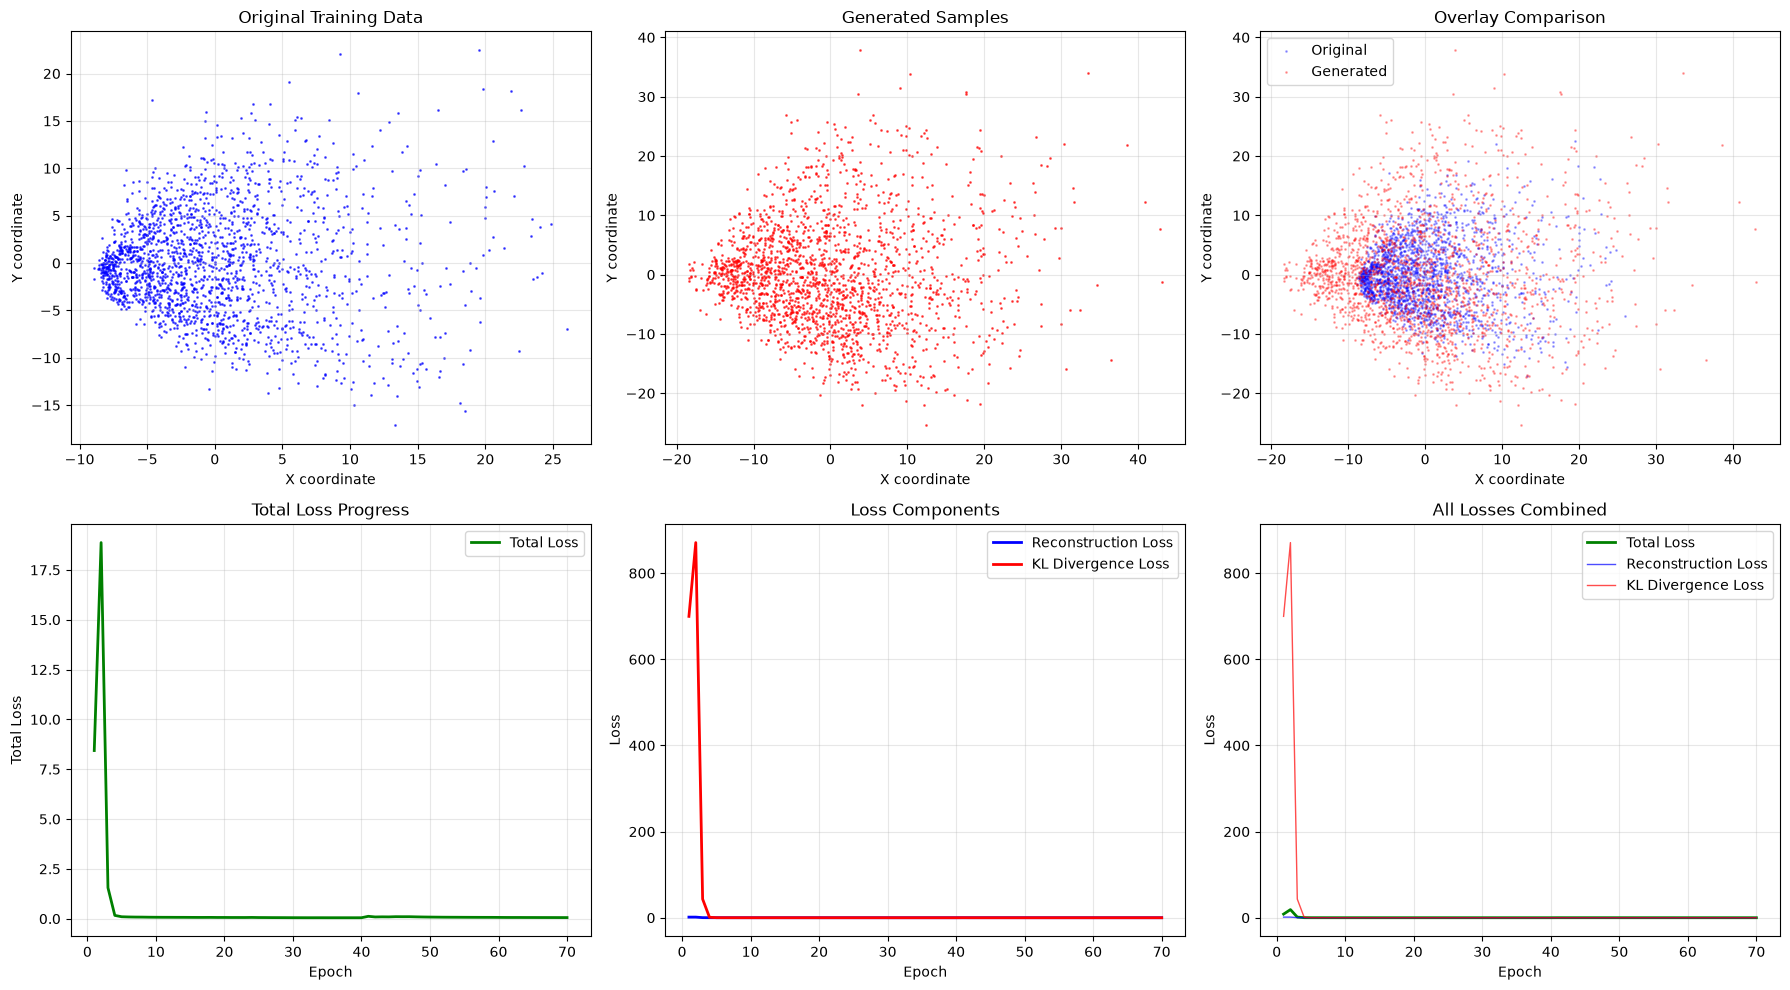

📈 Epoch 70 Summary:
   Total Loss: 0.0571
   Reconstruction Loss: 0.0493
   KL Divergence Loss: 0.0241
   Beta: 0.327
   Learning Rate: 0.000250

📊 Epoch 71/200
----------------------------------------
Epoch: 71 [0/60000 (0%)]	Total Loss: 0.056654	Recon Loss: 0.049004	KL Loss: 0.024506	Beta: 0.312
====> Epoch: 71 Average Total Loss: 0.0567, Average Recon Loss: 0.0489, Average KL Loss: 0.0248, Beta: 0.312
📈 Epoch 71 Summary:
   Total Loss: 0.0567
   Reconstruction Loss: 0.0489
   KL Divergence Loss: 0.0248
   Beta: 0.312
   Learning Rate: 0.000250

📊 Epoch 72/200
----------------------------------------
Epoch: 72 [0/60000 (0%)]	Total Loss: 0.056528	Recon Loss: 0.049113	KL Loss: 0.024978	Beta: 0.297
====> Epoch: 72 Average Total Loss: 0.0558, Average Recon Loss: 0.0484, Average KL Loss: 0.0252, Beta: 0.297
📈 Epoch 72 Summary:
   Total Loss: 0.0558
   Reconstruction Loss: 0.0484
   KL Divergence Loss: 0.0252
   Beta: 0.297
   Learning Rate: 0.000250

📊 Epoch 73/200
-----------------------

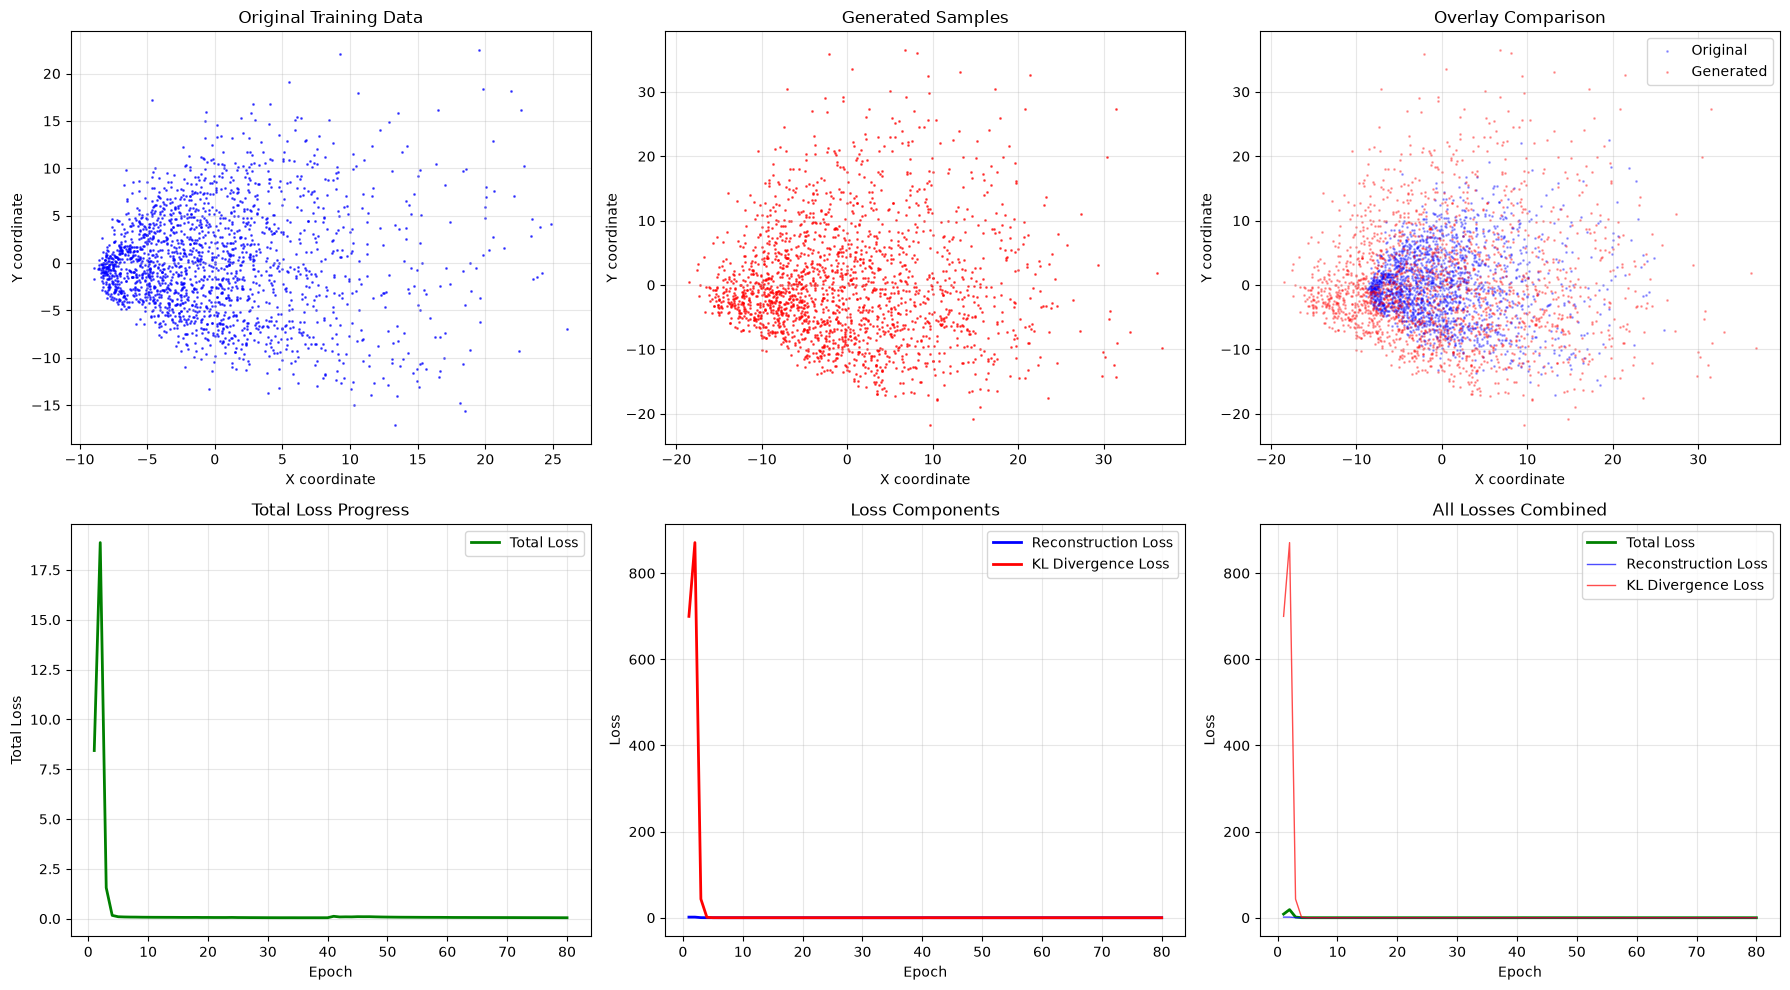

📈 Epoch 80 Summary:
   Total Loss: 0.0488
   Reconstruction Loss: 0.0432
   KL Divergence Loss: 0.0324
   Beta: 0.173
   Learning Rate: 0.000250

📊 Epoch 81/200
----------------------------------------
Epoch: 81 [0/60000 (0%)]	Total Loss: 0.048955	Recon Loss: 0.043699	KL Loss: 0.033271	Beta: 0.158
====> Epoch: 81 Average Total Loss: 0.0480, Average Recon Loss: 0.0426, Average KL Loss: 0.0339, Beta: 0.158
📈 Epoch 81 Summary:
   Total Loss: 0.0480
   Reconstruction Loss: 0.0426
   KL Divergence Loss: 0.0339
   Beta: 0.158
   Learning Rate: 0.000250

📊 Epoch 82/200
----------------------------------------
Epoch: 82 [0/60000 (0%)]	Total Loss: 0.048539	Recon Loss: 0.043589	KL Loss: 0.034481	Beta: 0.144
====> Epoch: 82 Average Total Loss: 0.0471, Average Recon Loss: 0.0420, Average KL Loss: 0.0353, Beta: 0.144
📈 Epoch 82 Summary:
   Total Loss: 0.0471
   Reconstruction Loss: 0.0420
   KL Divergence Loss: 0.0353
   Beta: 0.144
   Learning Rate: 0.000250

📊 Epoch 83/200
-----------------------

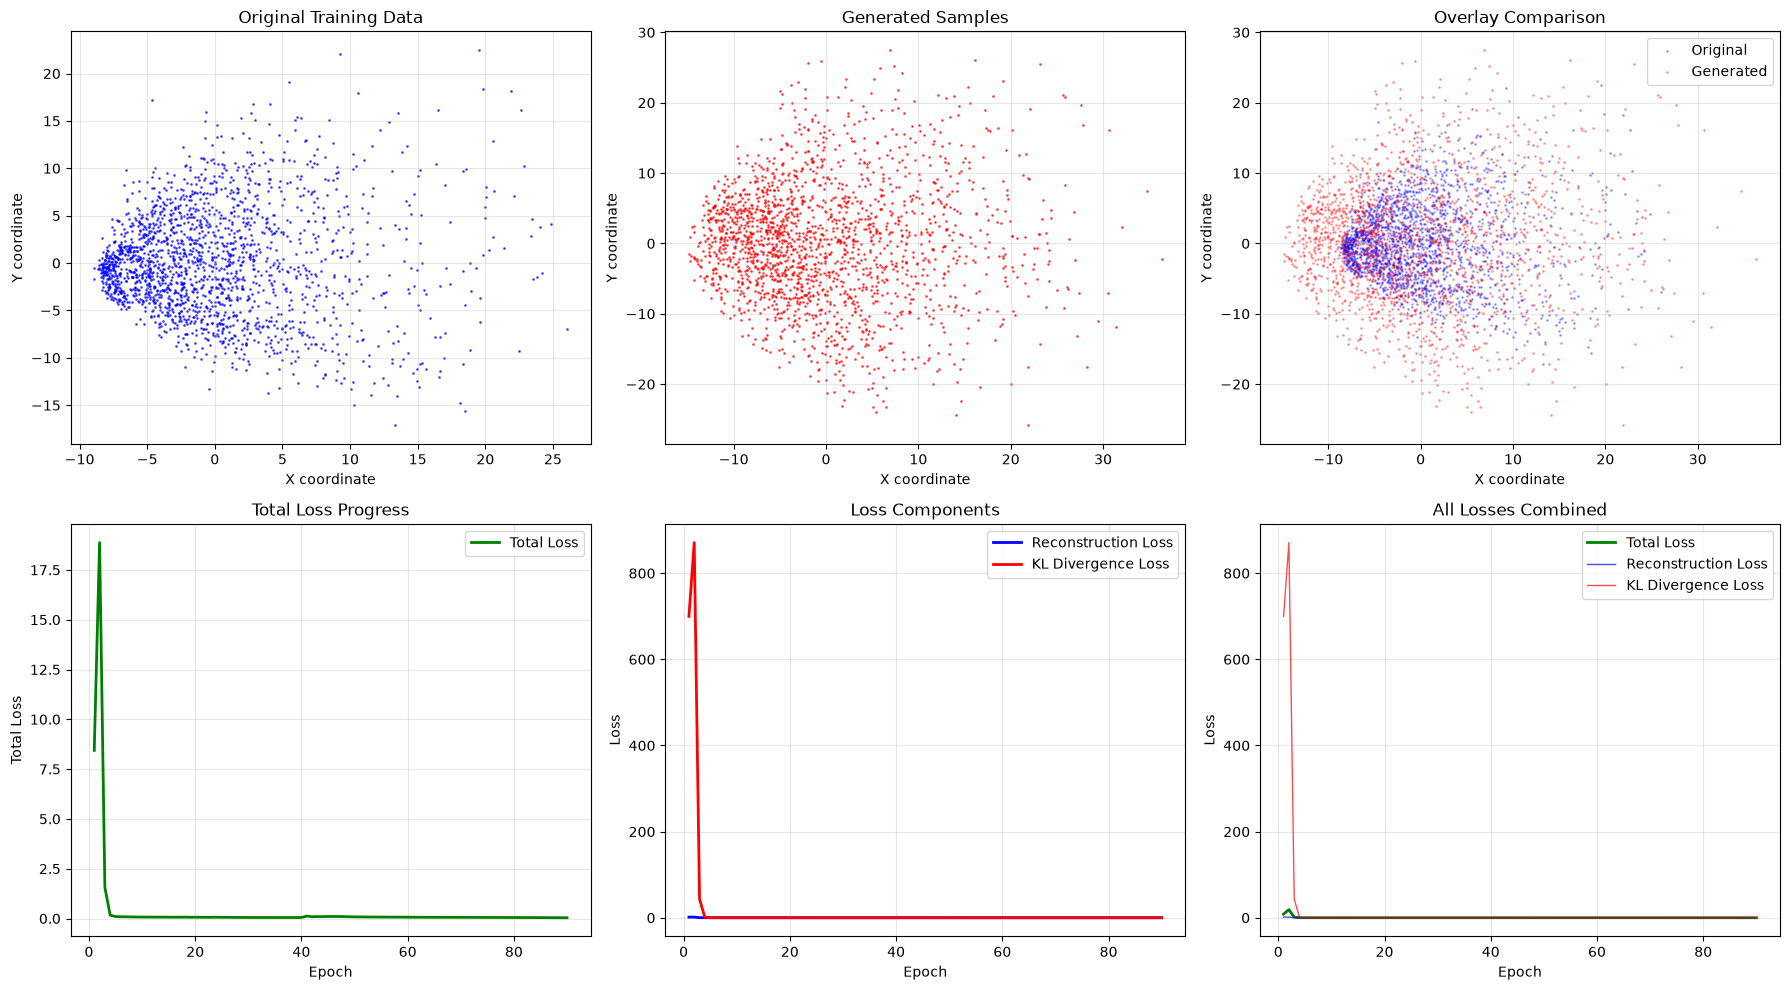

📈 Epoch 90 Summary:
   Total Loss: 0.0384
   Reconstruction Loss: 0.0360
   KL Divergence Loss: 0.0489
   Beta: 0.048
   Learning Rate: 0.000250

📊 Epoch 91/200
----------------------------------------
Epoch: 91 [0/60000 (0%)]	Total Loss: 0.037795	Recon Loss: 0.035840	KL Loss: 0.050234	Beta: 0.039
====> Epoch: 91 Average Total Loss: 0.0373, Average Recon Loss: 0.0353, Average KL Loss: 0.0512, Beta: 0.039
📈 Epoch 91 Summary:
   Total Loss: 0.0373
   Reconstruction Loss: 0.0353
   KL Divergence Loss: 0.0512
   Beta: 0.039
   Learning Rate: 0.000250

📊 Epoch 92/200
----------------------------------------
Epoch: 92 [0/60000 (0%)]	Total Loss: 0.036420	Recon Loss: 0.034799	KL Loss: 0.052421	Beta: 0.031
====> Epoch: 92 Average Total Loss: 0.0362, Average Recon Loss: 0.0345, Average KL Loss: 0.0537, Beta: 0.031
📈 Epoch 92 Summary:
   Total Loss: 0.0362
   Reconstruction Loss: 0.0345
   KL Divergence Loss: 0.0537
   Beta: 0.031
   Learning Rate: 0.000250

📊 Epoch 93/200
-----------------------

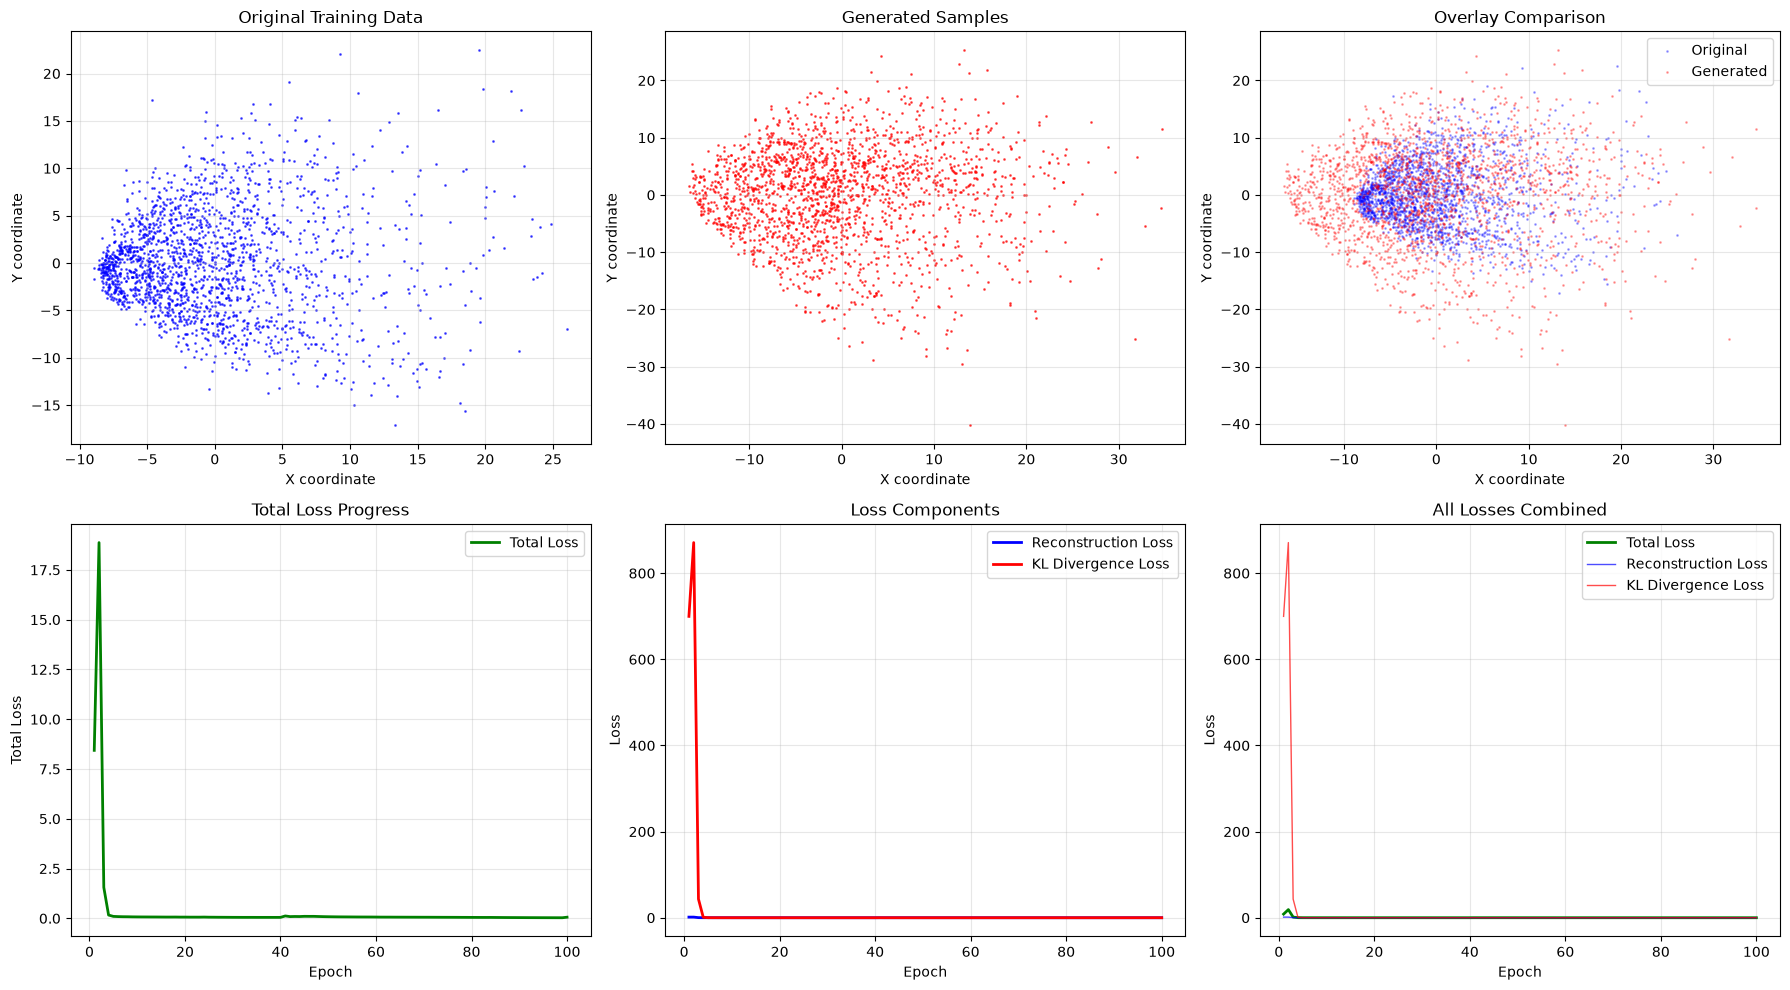

📈 Epoch 100 Summary:
   Total Loss: 0.0582
   Reconstruction Loss: 0.0366
   KL Divergence Loss: 0.0432
   Beta: 0.500
   Learning Rate: 0.000250

📊 Epoch 101/200
----------------------------------------
Epoch: 101 [0/60000 (0%)]	Total Loss: 0.053619	Recon Loss: 0.043393	KL Loss: 0.020472	Beta: 0.500
====> Epoch: 101 Average Total Loss: 0.0523, Average Recon Loss: 0.0410, Average KL Loss: 0.0227, Beta: 0.500
📈 Epoch 101 Summary:
   Total Loss: 0.0523
   Reconstruction Loss: 0.0410
   KL Divergence Loss: 0.0227
   Beta: 0.500
   Learning Rate: 0.000250

📊 Epoch 102/200
----------------------------------------
Epoch: 102 [0/60000 (0%)]	Total Loss: 0.051035	Recon Loss: 0.038456	KL Loss: 0.025259	Beta: 0.498
====> Epoch: 102 Average Total Loss: 0.0506, Average Recon Loss: 0.0381, Average KL Loss: 0.0252, Beta: 0.498
📈 Epoch 102 Summary:
   Total Loss: 0.0506
   Reconstruction Loss: 0.0381
   KL Divergence Loss: 0.0252
   Beta: 0.498
   Learning Rate: 0.000250

📊 Epoch 103/200
-------------

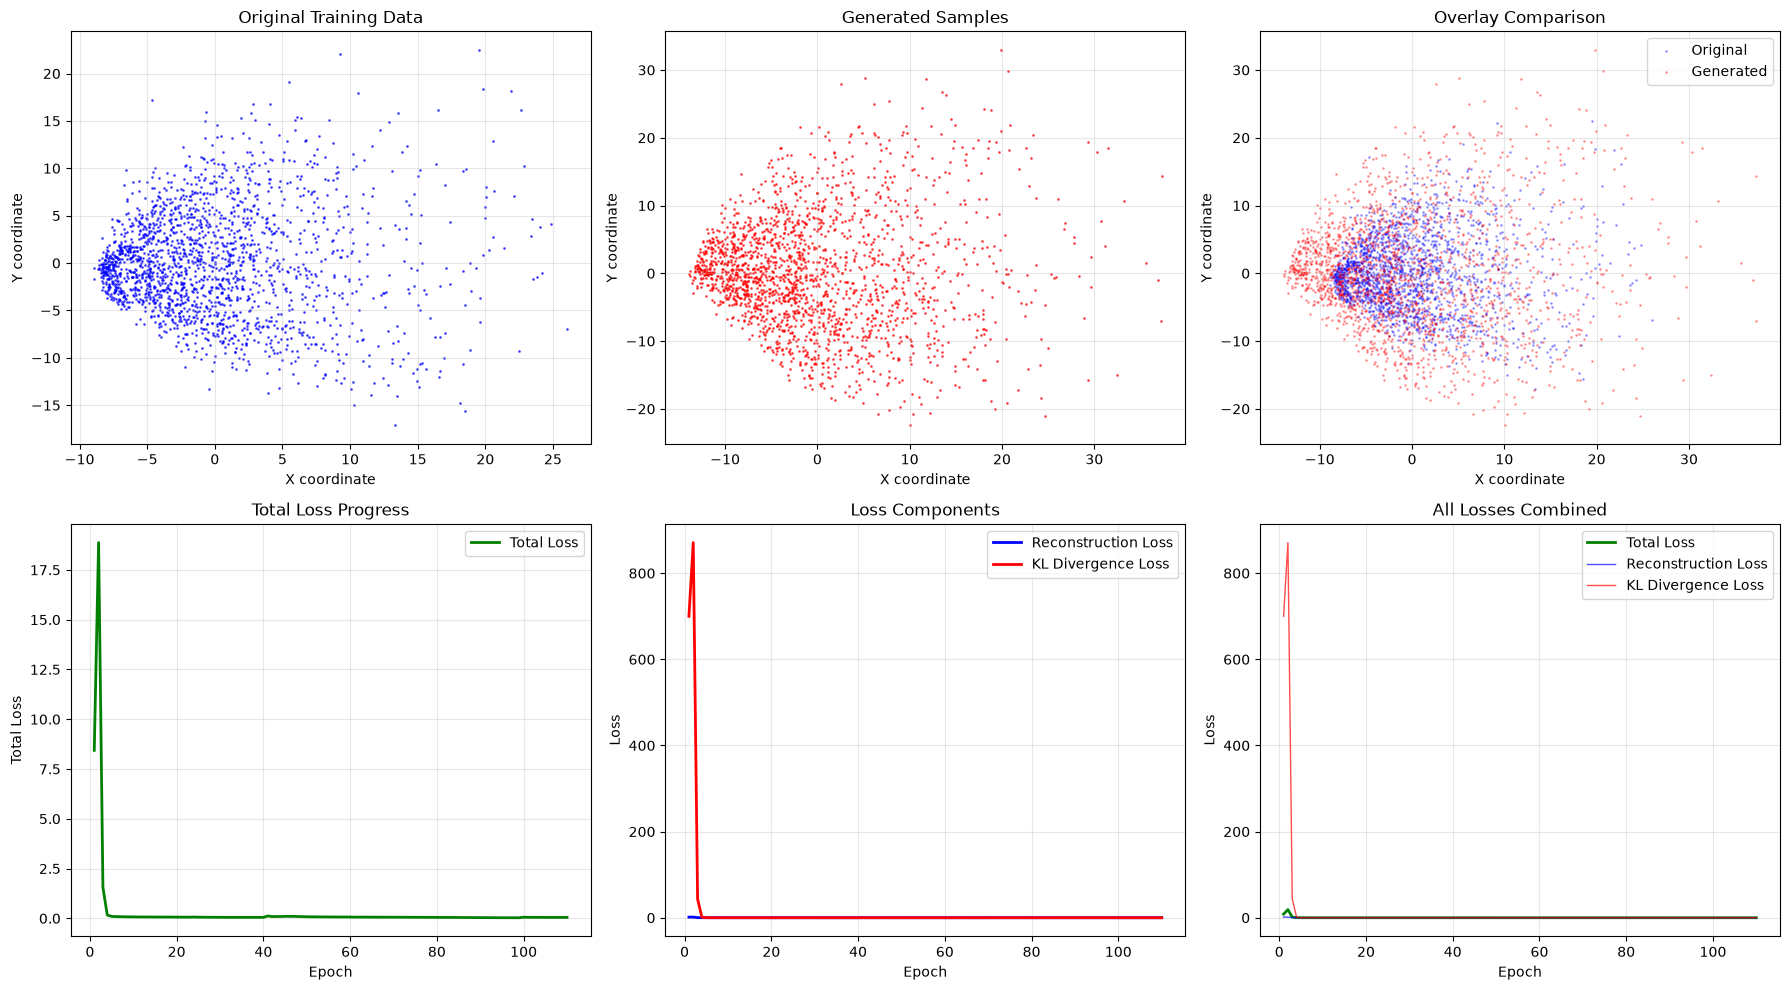

📈 Epoch 110 Summary:
   Total Loss: 0.0468
   Reconstruction Loss: 0.0348
   KL Divergence Loss: 0.0267
   Beta: 0.452
   Learning Rate: 0.000250

📊 Epoch 111/200
----------------------------------------
Epoch: 111 [0/60000 (0%)]	Total Loss: 0.045981	Recon Loss: 0.034056	KL Loss: 0.026941	Beta: 0.443
====> Epoch: 111 Average Total Loss: 0.1240, Average Recon Loss: 0.1121, Average KL Loss: 0.0270, Beta: 0.443
📈 Epoch 111 Summary:
   Total Loss: 0.1240
   Reconstruction Loss: 0.1121
   KL Divergence Loss: 0.0270
   Beta: 0.443
   Learning Rate: 0.000250

📊 Epoch 112/200
----------------------------------------
Epoch: 112 [0/60000 (0%)]	Total Loss: 0.057752	Recon Loss: 0.045709	KL Loss: 0.027862	Beta: 0.432
====> Epoch: 112 Average Total Loss: 0.0722, Average Recon Loss: 0.0595, Average KL Loss: 0.0294, Beta: 0.432
📈 Epoch 112 Summary:
   Total Loss: 0.0722
   Reconstruction Loss: 0.0595
   KL Divergence Loss: 0.0294
   Beta: 0.432
   Learning Rate: 0.000250

📊 Epoch 113/200
-------------

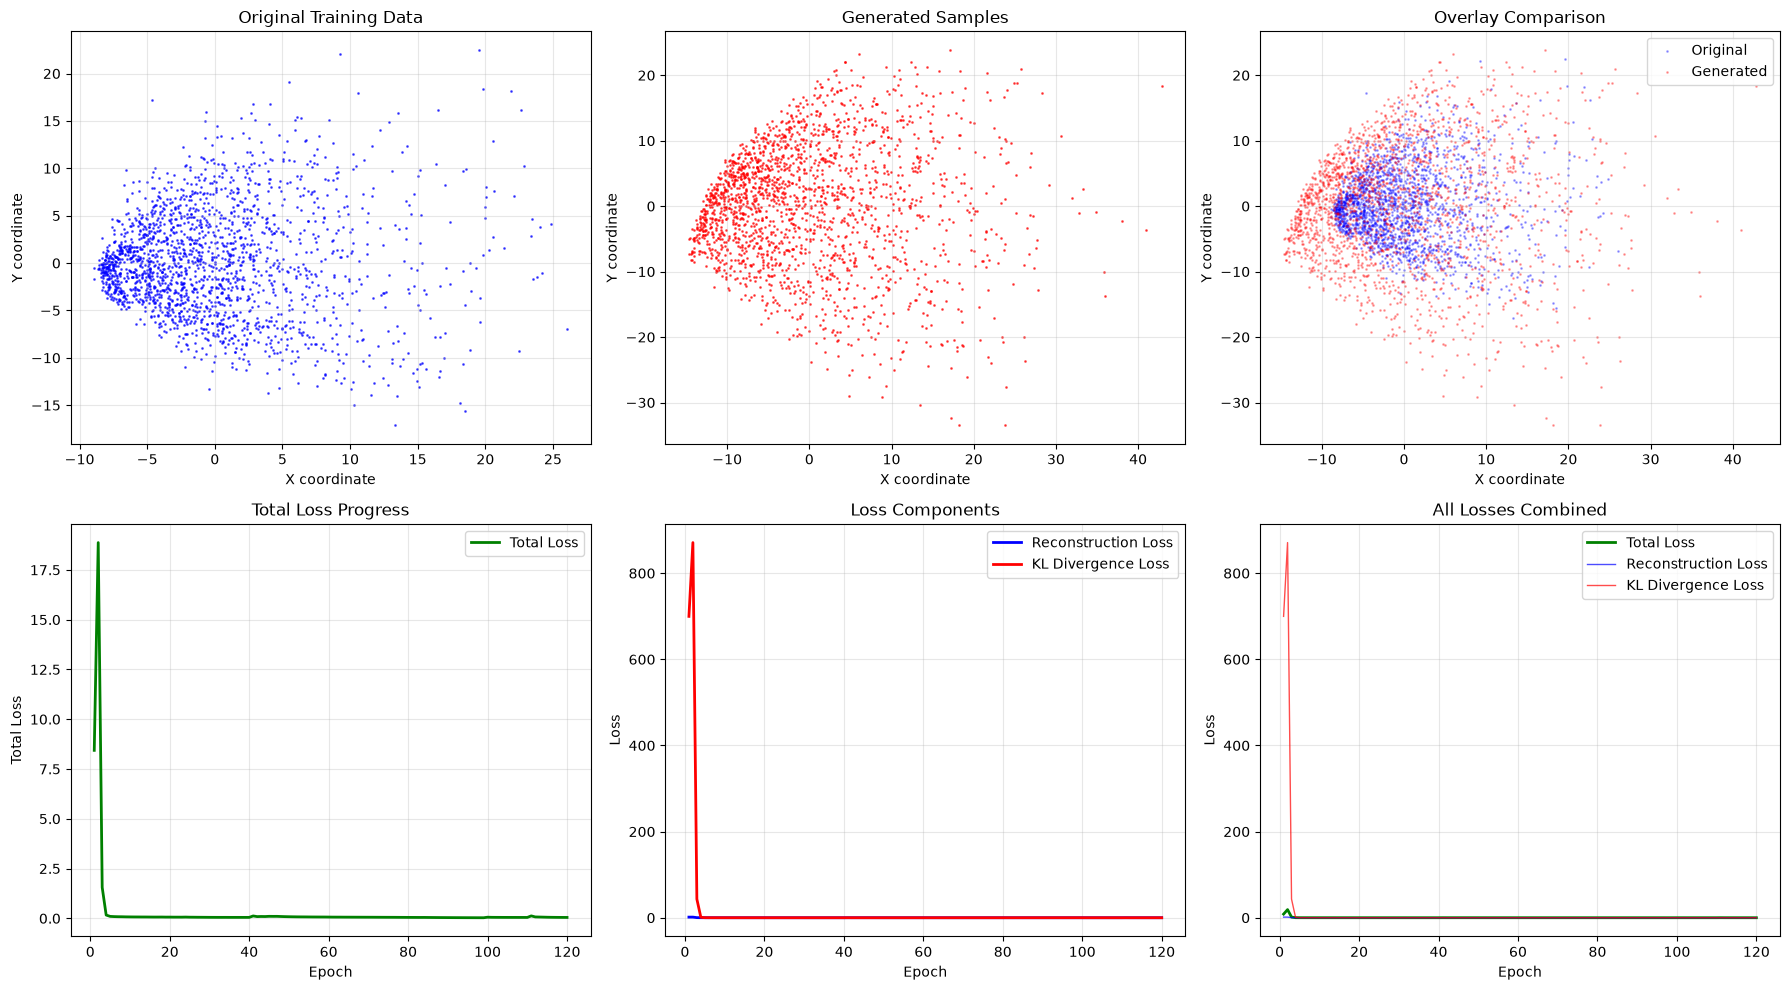

📈 Epoch 120 Summary:
   Total Loss: 0.0466
   Reconstruction Loss: 0.0379
   KL Divergence Loss: 0.0266
   Beta: 0.327
   Learning Rate: 0.000125

📊 Epoch 121/200
----------------------------------------
Epoch: 121 [0/60000 (0%)]	Total Loss: 0.045752	Recon Loss: 0.037240	KL Loss: 0.027268	Beta: 0.312
====> Epoch: 121 Average Total Loss: 0.0456, Average Recon Loss: 0.0370, Average KL Loss: 0.0275, Beta: 0.312
📈 Epoch 121 Summary:
   Total Loss: 0.0456
   Reconstruction Loss: 0.0370
   KL Divergence Loss: 0.0275
   Beta: 0.312
   Learning Rate: 0.000125

📊 Epoch 122/200
----------------------------------------
Epoch: 122 [0/60000 (0%)]	Total Loss: 0.044892	Recon Loss: 0.036631	KL Loss: 0.027829	Beta: 0.297
====> Epoch: 122 Average Total Loss: 0.0449, Average Recon Loss: 0.0366, Average KL Loss: 0.0281, Beta: 0.297
📈 Epoch 122 Summary:
   Total Loss: 0.0449
   Reconstruction Loss: 0.0366
   KL Divergence Loss: 0.0281
   Beta: 0.297
   Learning Rate: 0.000125

📊 Epoch 123/200
-------------

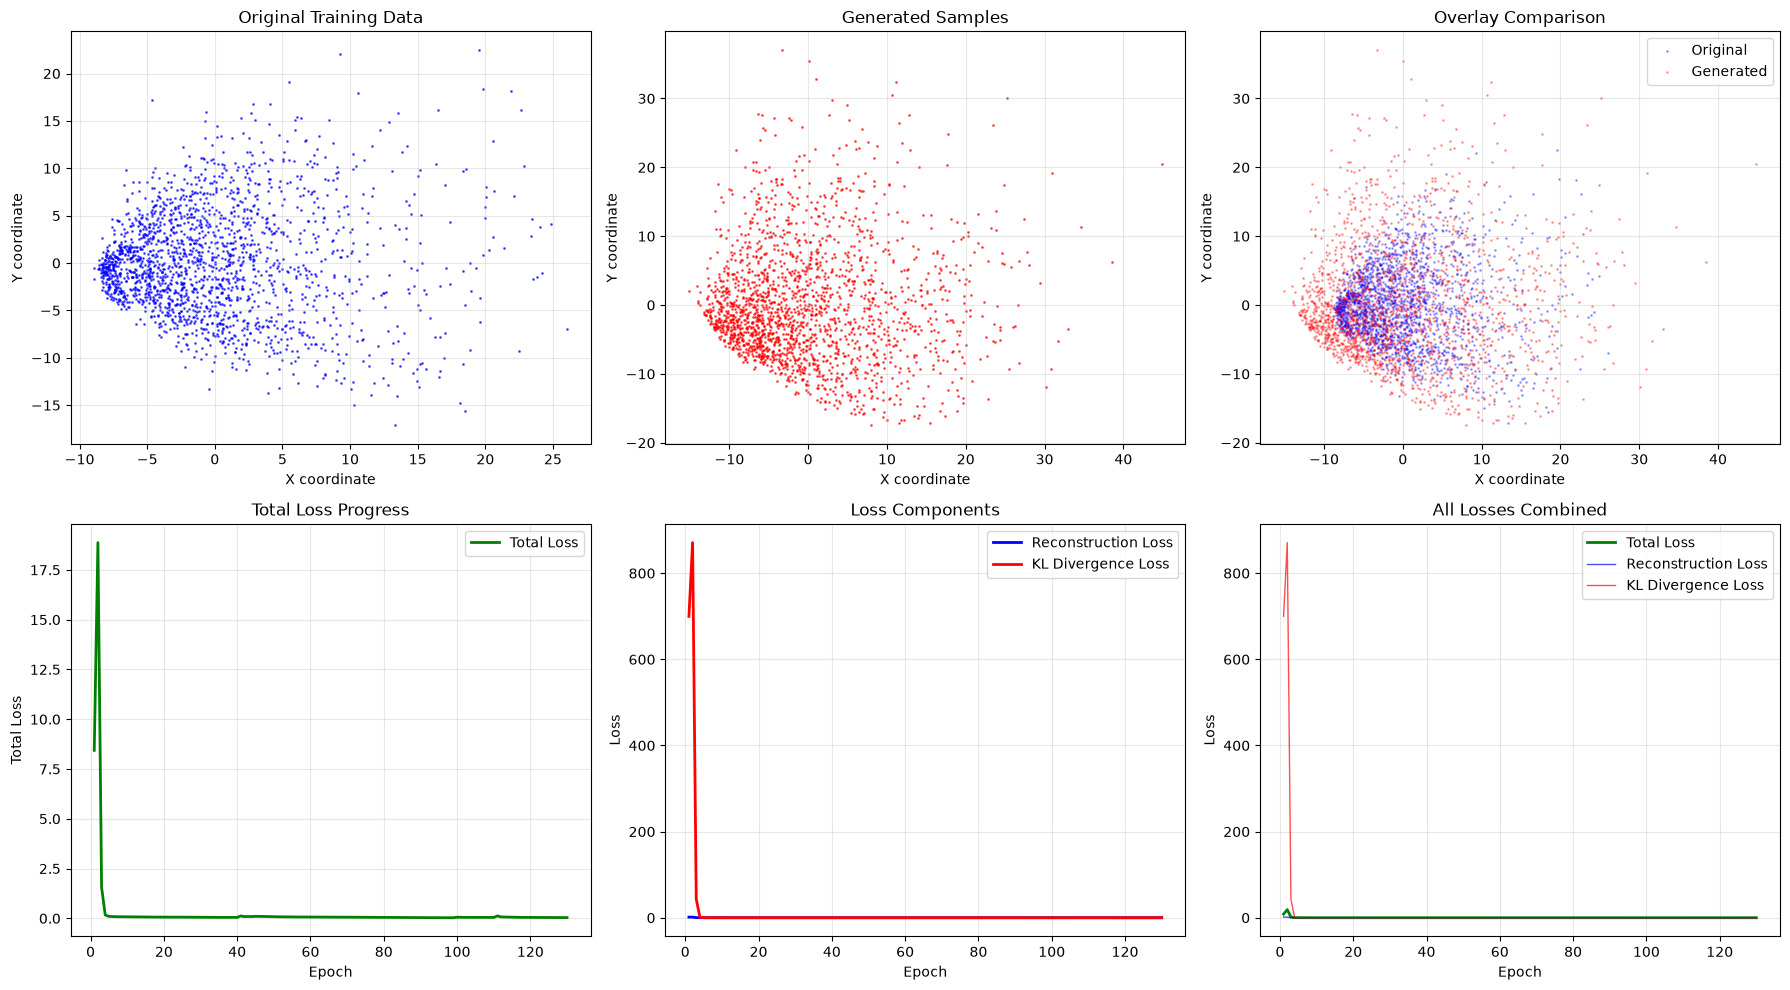

📈 Epoch 130 Summary:
   Total Loss: 0.0391
   Reconstruction Loss: 0.0331
   KL Divergence Loss: 0.0348
   Beta: 0.173
   Learning Rate: 0.000125

📊 Epoch 131/200
----------------------------------------
Epoch: 131 [0/60000 (0%)]	Total Loss: 0.038644	Recon Loss: 0.033037	KL Loss: 0.035493	Beta: 0.158
====> Epoch: 131 Average Total Loss: 0.0386, Average Recon Loss: 0.0329, Average KL Loss: 0.0359, Beta: 0.158
📈 Epoch 131 Summary:
   Total Loss: 0.0386
   Reconstruction Loss: 0.0329
   KL Divergence Loss: 0.0359
   Beta: 0.158
   Learning Rate: 0.000125

📊 Epoch 132/200
----------------------------------------
Epoch: 132 [0/60000 (0%)]	Total Loss: 0.037788	Recon Loss: 0.032541	KL Loss: 0.036554	Beta: 0.144
====> Epoch: 132 Average Total Loss: 0.0379, Average Recon Loss: 0.0325, Average KL Loss: 0.0370, Beta: 0.144
📈 Epoch 132 Summary:
   Total Loss: 0.0379
   Reconstruction Loss: 0.0325
   KL Divergence Loss: 0.0370
   Beta: 0.144
   Learning Rate: 0.000125

📊 Epoch 133/200
-------------

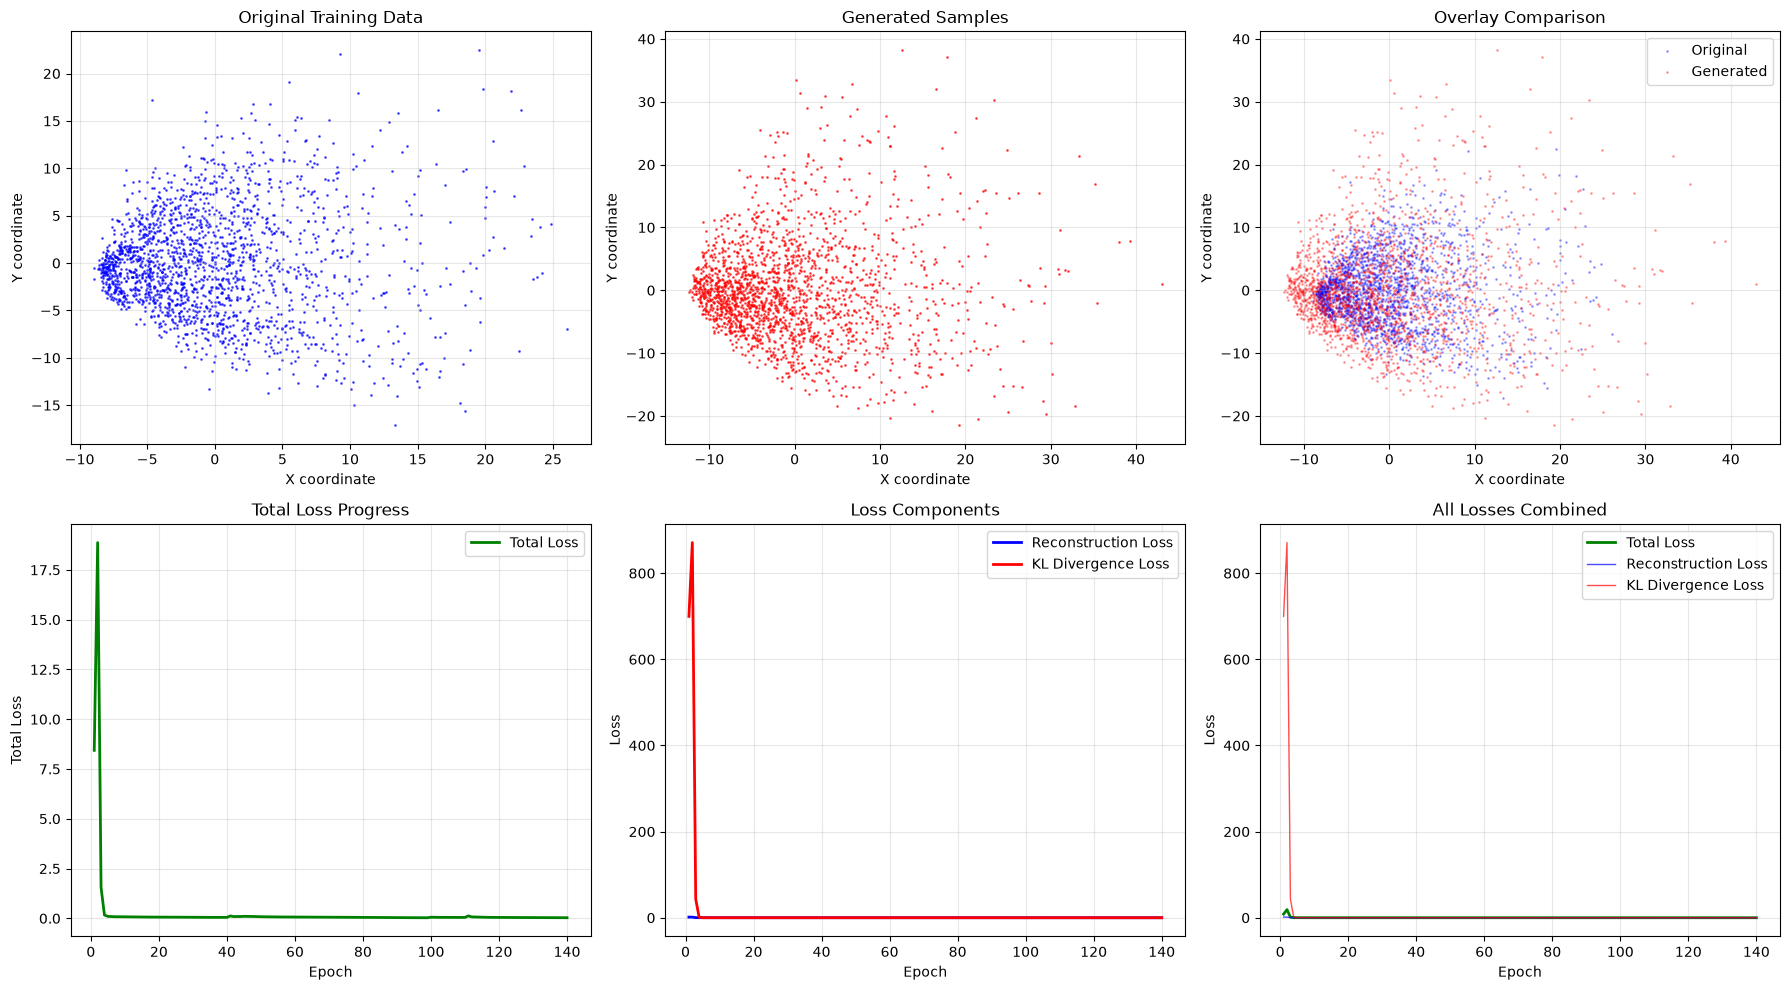

📈 Epoch 140 Summary:
   Total Loss: 0.0327
   Reconstruction Loss: 0.0304
   KL Divergence Loss: 0.0483
   Beta: 0.048
   Learning Rate: 0.000125

📊 Epoch 141/200
----------------------------------------
Epoch: 141 [0/60000 (0%)]	Total Loss: 0.032116	Recon Loss: 0.030193	KL Loss: 0.049417	Beta: 0.039
====> Epoch: 141 Average Total Loss: 0.0320, Average Recon Loss: 0.0301, Average KL Loss: 0.0503, Beta: 0.039
📈 Epoch 141 Summary:
   Total Loss: 0.0320
   Reconstruction Loss: 0.0301
   KL Divergence Loss: 0.0503
   Beta: 0.039
   Learning Rate: 0.000063

📊 Epoch 142/200
----------------------------------------
Epoch: 142 [0/60000 (0%)]	Total Loss: 0.031618	Recon Loss: 0.030028	KL Loss: 0.051397	Beta: 0.031
====> Epoch: 142 Average Total Loss: 0.0316, Average Recon Loss: 0.0300, Average KL Loss: 0.0518, Beta: 0.031
📈 Epoch 142 Summary:
   Total Loss: 0.0316
   Reconstruction Loss: 0.0300
   KL Divergence Loss: 0.0518
   Beta: 0.031
   Learning Rate: 0.000063

📊 Epoch 143/200
-------------

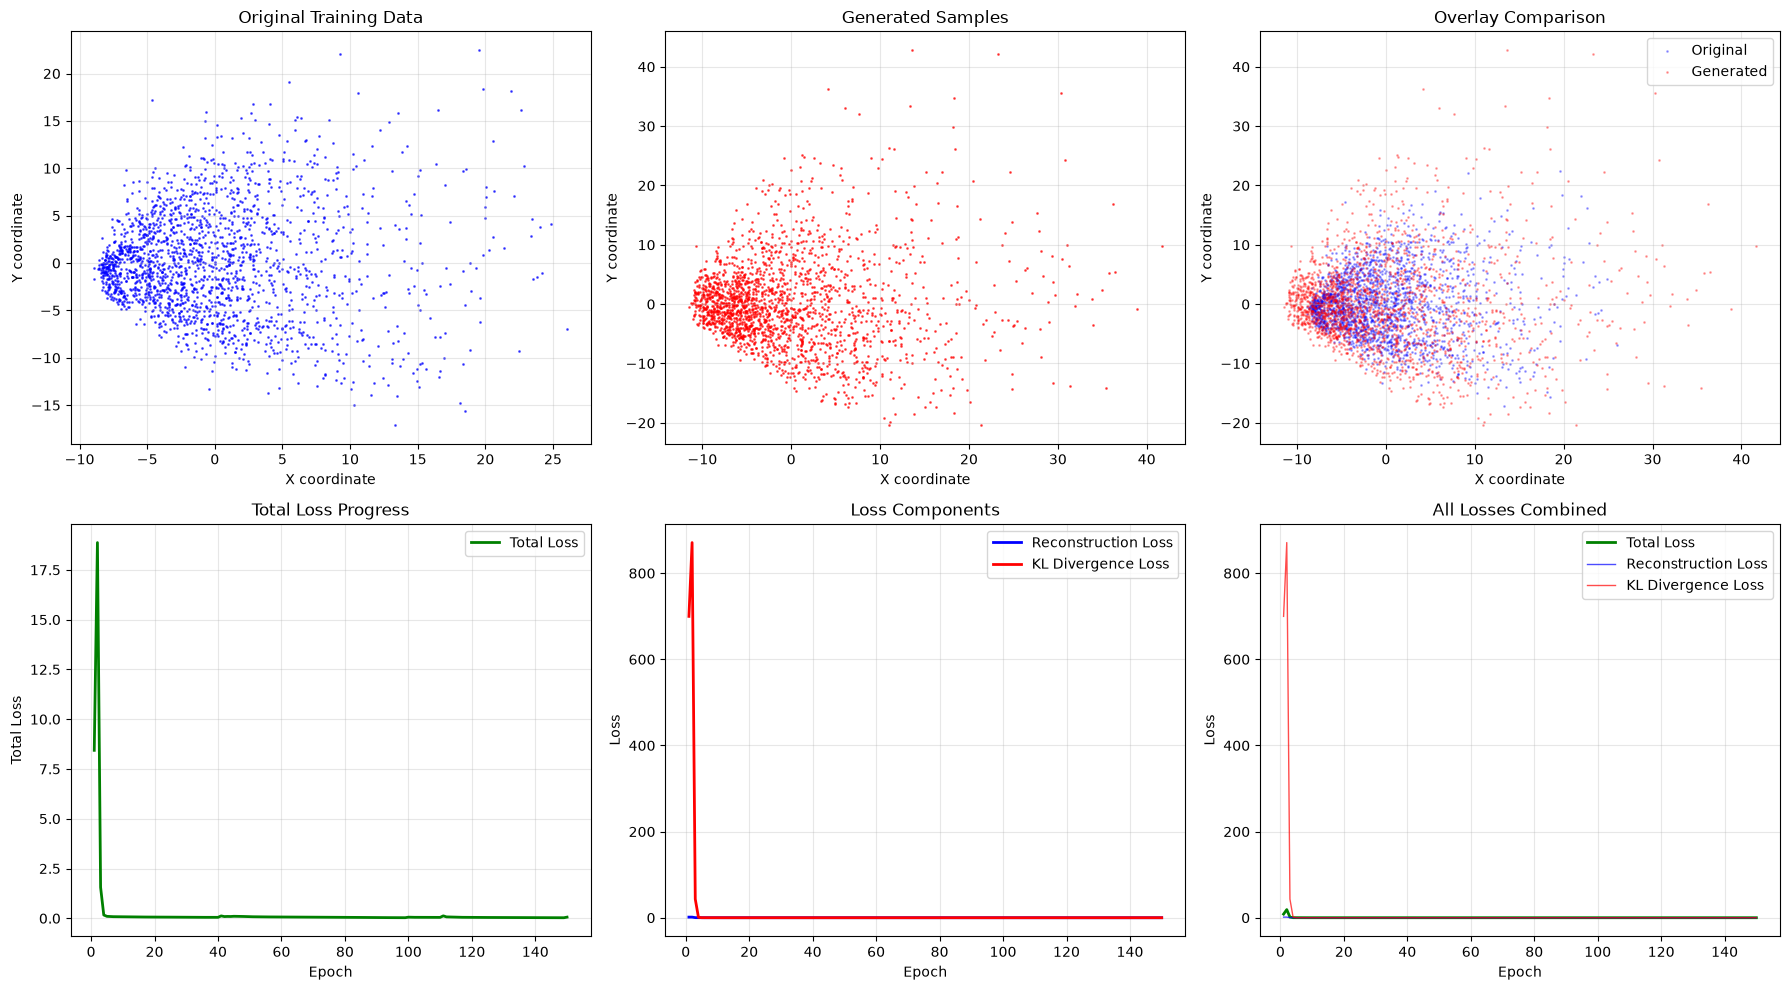

📈 Epoch 150 Summary:
   Total Loss: 0.0593
   Reconstruction Loss: 0.0291
   KL Divergence Loss: 0.0604
   Beta: 0.500
   Learning Rate: 0.000063

📊 Epoch 151/200
----------------------------------------
Epoch: 151 [0/60000 (0%)]	Total Loss: 0.052167	Recon Loss: 0.029986	KL Loss: 0.044406	Beta: 0.500
====> Epoch: 151 Average Total Loss: 0.0496, Average Recon Loss: 0.0316, Average KL Loss: 0.0361, Beta: 0.500
📈 Epoch 151 Summary:
   Total Loss: 0.0496
   Reconstruction Loss: 0.0316
   KL Divergence Loss: 0.0361
   Beta: 0.500
   Learning Rate: 0.000063

📊 Epoch 152/200
----------------------------------------
Epoch: 152 [0/60000 (0%)]	Total Loss: 0.048285	Recon Loss: 0.034088	KL Loss: 0.028506	Beta: 0.498
====> Epoch: 152 Average Total Loss: 0.0482, Average Recon Loss: 0.0352, Average KL Loss: 0.0261, Beta: 0.498
📈 Epoch 152 Summary:
   Total Loss: 0.0482
   Reconstruction Loss: 0.0352
   KL Divergence Loss: 0.0261
   Beta: 0.498
   Learning Rate: 0.000063

📊 Epoch 153/200
-------------

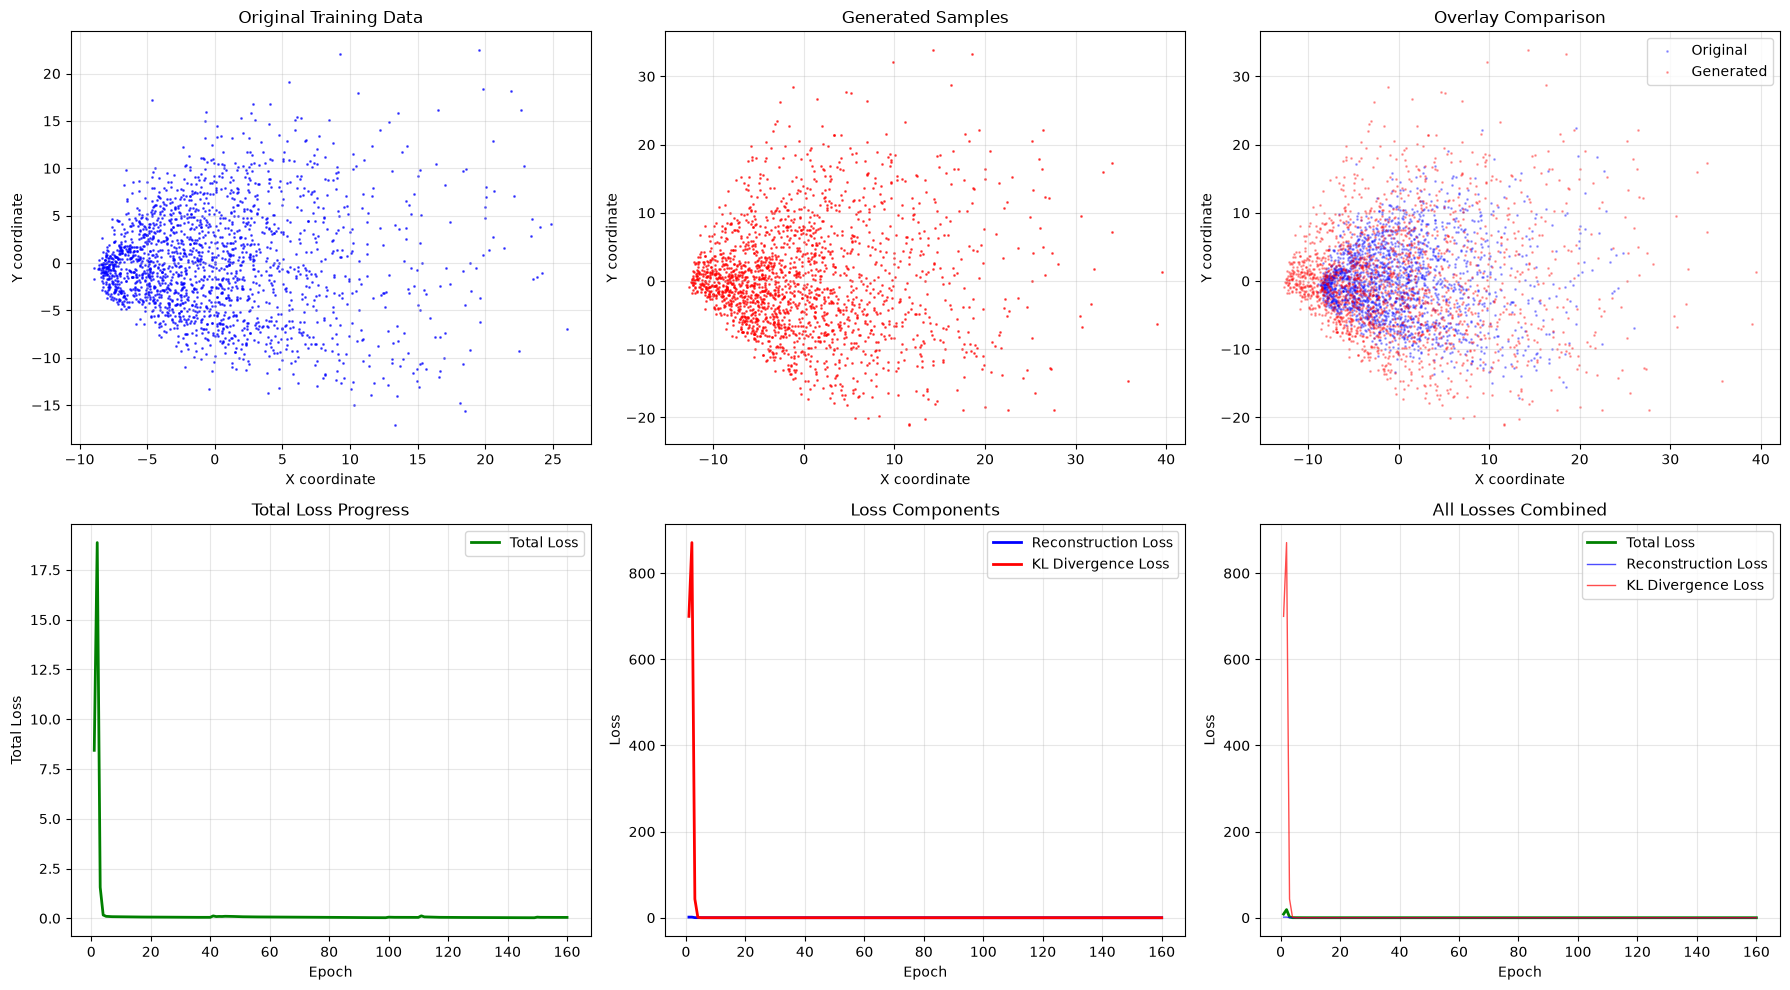

📈 Epoch 160 Summary:
   Total Loss: 0.0456
   Reconstruction Loss: 0.0333
   KL Divergence Loss: 0.0272
   Beta: 0.452
   Learning Rate: 0.000063

📊 Epoch 161/200
----------------------------------------
Epoch: 161 [0/60000 (0%)]	Total Loss: 0.045397	Recon Loss: 0.033301	KL Loss: 0.027326	Beta: 0.443
====> Epoch: 161 Average Total Loss: 0.0453, Average Recon Loss: 0.0332, Average KL Loss: 0.0274, Beta: 0.443
📈 Epoch 161 Summary:
   Total Loss: 0.0453
   Reconstruction Loss: 0.0332
   KL Divergence Loss: 0.0274
   Beta: 0.443
   Learning Rate: 0.000063

📊 Epoch 162/200
----------------------------------------
Epoch: 162 [0/60000 (0%)]	Total Loss: 0.045022	Recon Loss: 0.033155	KL Loss: 0.027454	Beta: 0.432
====> Epoch: 162 Average Total Loss: 0.0450, Average Recon Loss: 0.0331, Average KL Loss: 0.0276, Beta: 0.432
📈 Epoch 162 Summary:
   Total Loss: 0.0450
   Reconstruction Loss: 0.0331
   KL Divergence Loss: 0.0276
   Beta: 0.432
   Learning Rate: 0.000063

📊 Epoch 163/200
-------------

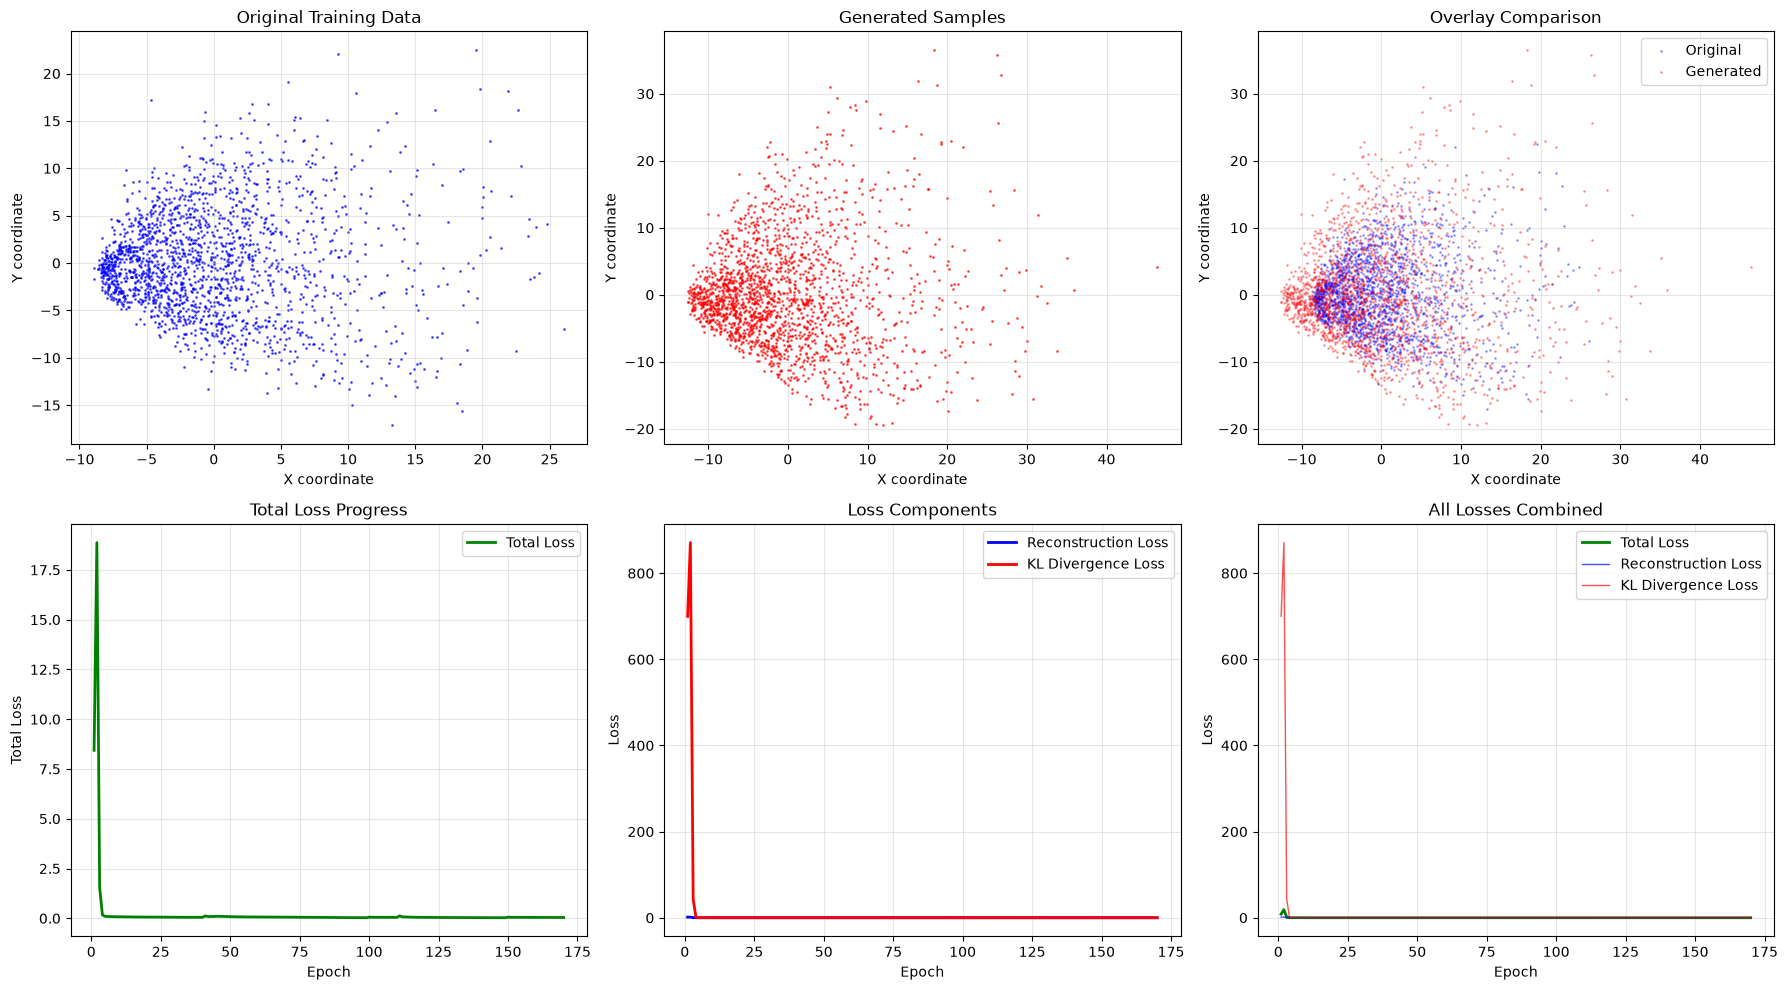

📈 Epoch 170 Summary:
   Total Loss: 0.0415
   Reconstruction Loss: 0.0317
   KL Divergence Loss: 0.0302
   Beta: 0.327
   Learning Rate: 0.000031

📊 Epoch 171/200
----------------------------------------
Epoch: 171 [0/60000 (0%)]	Total Loss: 0.041094	Recon Loss: 0.031582	KL Loss: 0.030469	Beta: 0.312
====> Epoch: 171 Average Total Loss: 0.0411, Average Recon Loss: 0.0316, Average KL Loss: 0.0306, Beta: 0.312
📈 Epoch 171 Summary:
   Total Loss: 0.0411
   Reconstruction Loss: 0.0316
   KL Divergence Loss: 0.0306
   Beta: 0.312
   Learning Rate: 0.000031

📊 Epoch 172/200
----------------------------------------
Epoch: 172 [0/60000 (0%)]	Total Loss: 0.040722	Recon Loss: 0.031615	KL Loss: 0.030681	Beta: 0.297
====> Epoch: 172 Average Total Loss: 0.0406, Average Recon Loss: 0.0315, Average KL Loss: 0.0309, Beta: 0.297
📈 Epoch 172 Summary:
   Total Loss: 0.0406
   Reconstruction Loss: 0.0315
   KL Divergence Loss: 0.0309
   Beta: 0.297
   Learning Rate: 0.000031

📊 Epoch 173/200
-------------

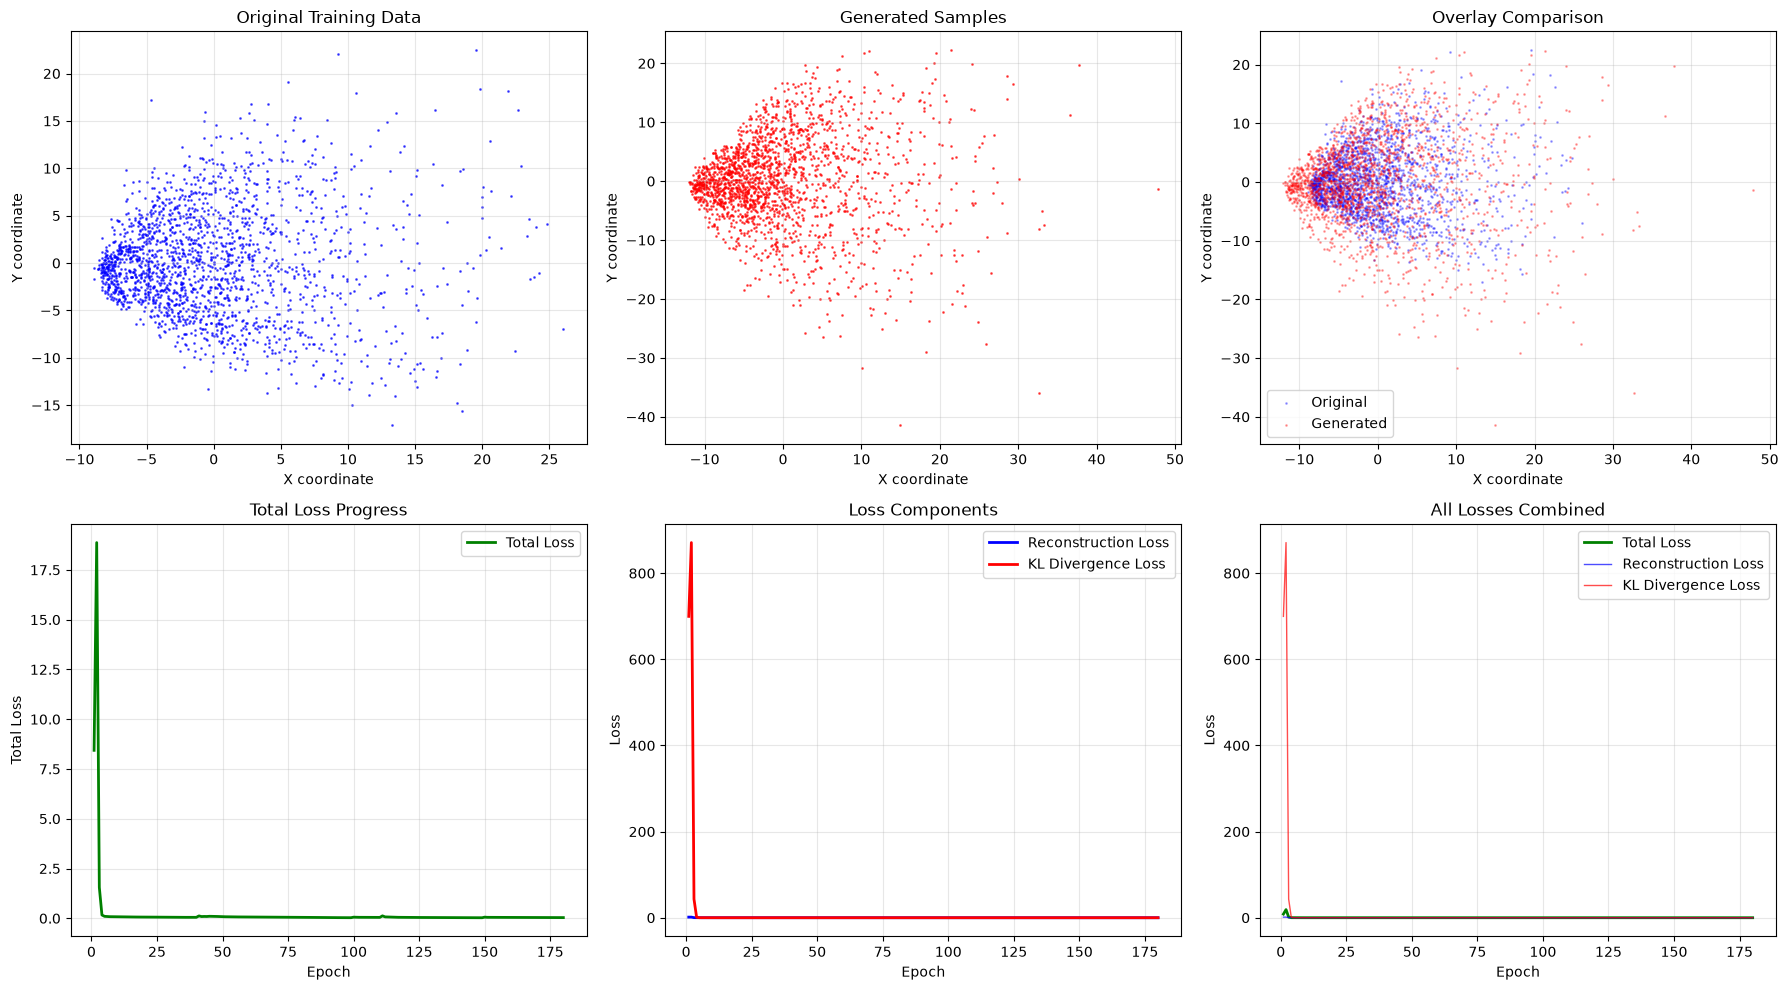

📈 Epoch 180 Summary:
   Total Loss: 0.0361
   Reconstruction Loss: 0.0300
   KL Divergence Loss: 0.0353
   Beta: 0.173
   Learning Rate: 0.000031

📊 Epoch 181/200
----------------------------------------
Epoch: 181 [0/60000 (0%)]	Total Loss: 0.035451	Recon Loss: 0.029811	KL Loss: 0.035705	Beta: 0.158
====> Epoch: 181 Average Total Loss: 0.0355, Average Recon Loss: 0.0298, Average KL Loss: 0.0360, Beta: 0.158
📈 Epoch 181 Summary:
   Total Loss: 0.0355
   Reconstruction Loss: 0.0298
   KL Divergence Loss: 0.0360
   Beta: 0.158
   Learning Rate: 0.000031

📊 Epoch 182/200
----------------------------------------
Epoch: 182 [0/60000 (0%)]	Total Loss: 0.034740	Recon Loss: 0.029507	KL Loss: 0.036453	Beta: 0.144
====> Epoch: 182 Average Total Loss: 0.0349, Average Recon Loss: 0.0297, Average KL Loss: 0.0368, Beta: 0.144
📈 Epoch 182 Summary:
   Total Loss: 0.0349
   Reconstruction Loss: 0.0297
   KL Divergence Loss: 0.0368
   Beta: 0.144
   Learning Rate: 0.000031

📊 Epoch 183/200
-------------

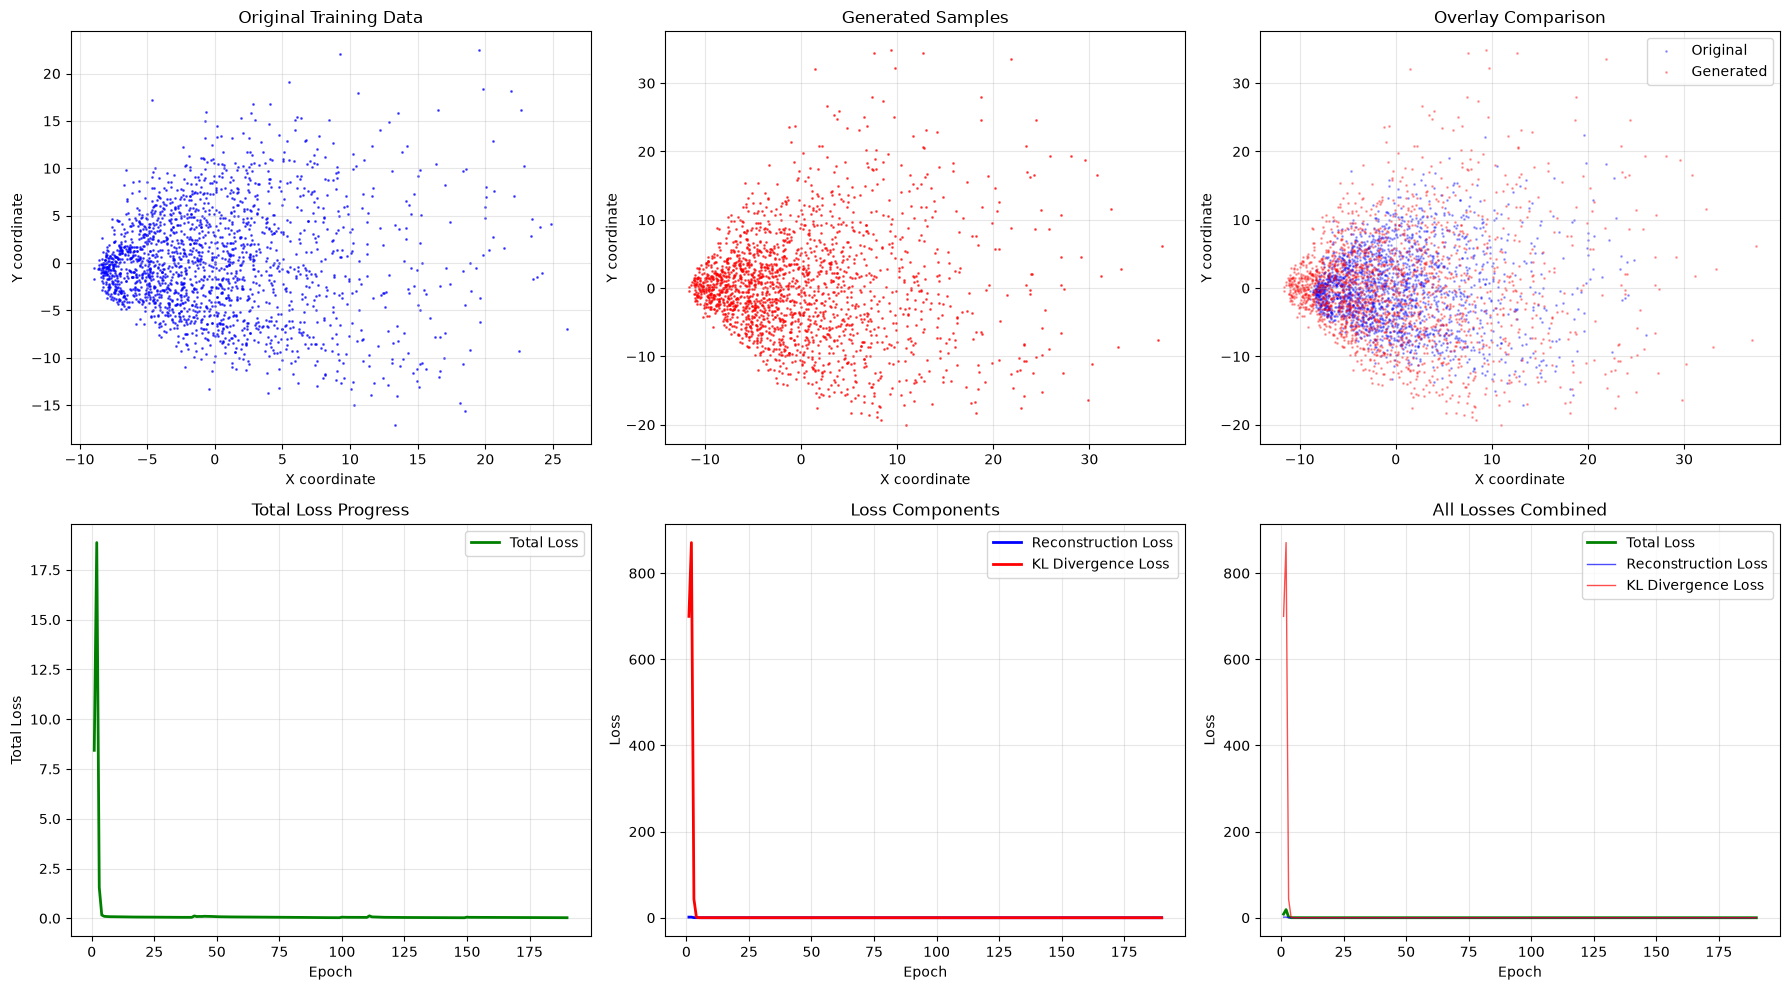

📈 Epoch 190 Summary:
   Total Loss: 0.0306
   Reconstruction Loss: 0.0285
   KL Divergence Loss: 0.0449
   Beta: 0.048
   Learning Rate: 0.000031

📊 Epoch 191/200
----------------------------------------
Epoch: 191 [0/60000 (0%)]	Total Loss: 0.030048	Recon Loss: 0.028271	KL Loss: 0.045644	Beta: 0.039
====> Epoch: 191 Average Total Loss: 0.0302, Average Recon Loss: 0.0284, Average KL Loss: 0.0462, Beta: 0.039
📈 Epoch 191 Summary:
   Total Loss: 0.0302
   Reconstruction Loss: 0.0284
   KL Divergence Loss: 0.0462
   Beta: 0.039
   Learning Rate: 0.000016

📊 Epoch 192/200
----------------------------------------
Epoch: 192 [0/60000 (0%)]	Total Loss: 0.029801	Recon Loss: 0.028348	KL Loss: 0.046971	Beta: 0.031
====> Epoch: 192 Average Total Loss: 0.0296, Average Recon Loss: 0.0282, Average KL Loss: 0.0473, Beta: 0.031
📈 Epoch 192 Summary:
   Total Loss: 0.0296
   Reconstruction Loss: 0.0282
   KL Divergence Loss: 0.0473
   Beta: 0.031
   Learning Rate: 0.000016

📊 Epoch 193/200
-------------

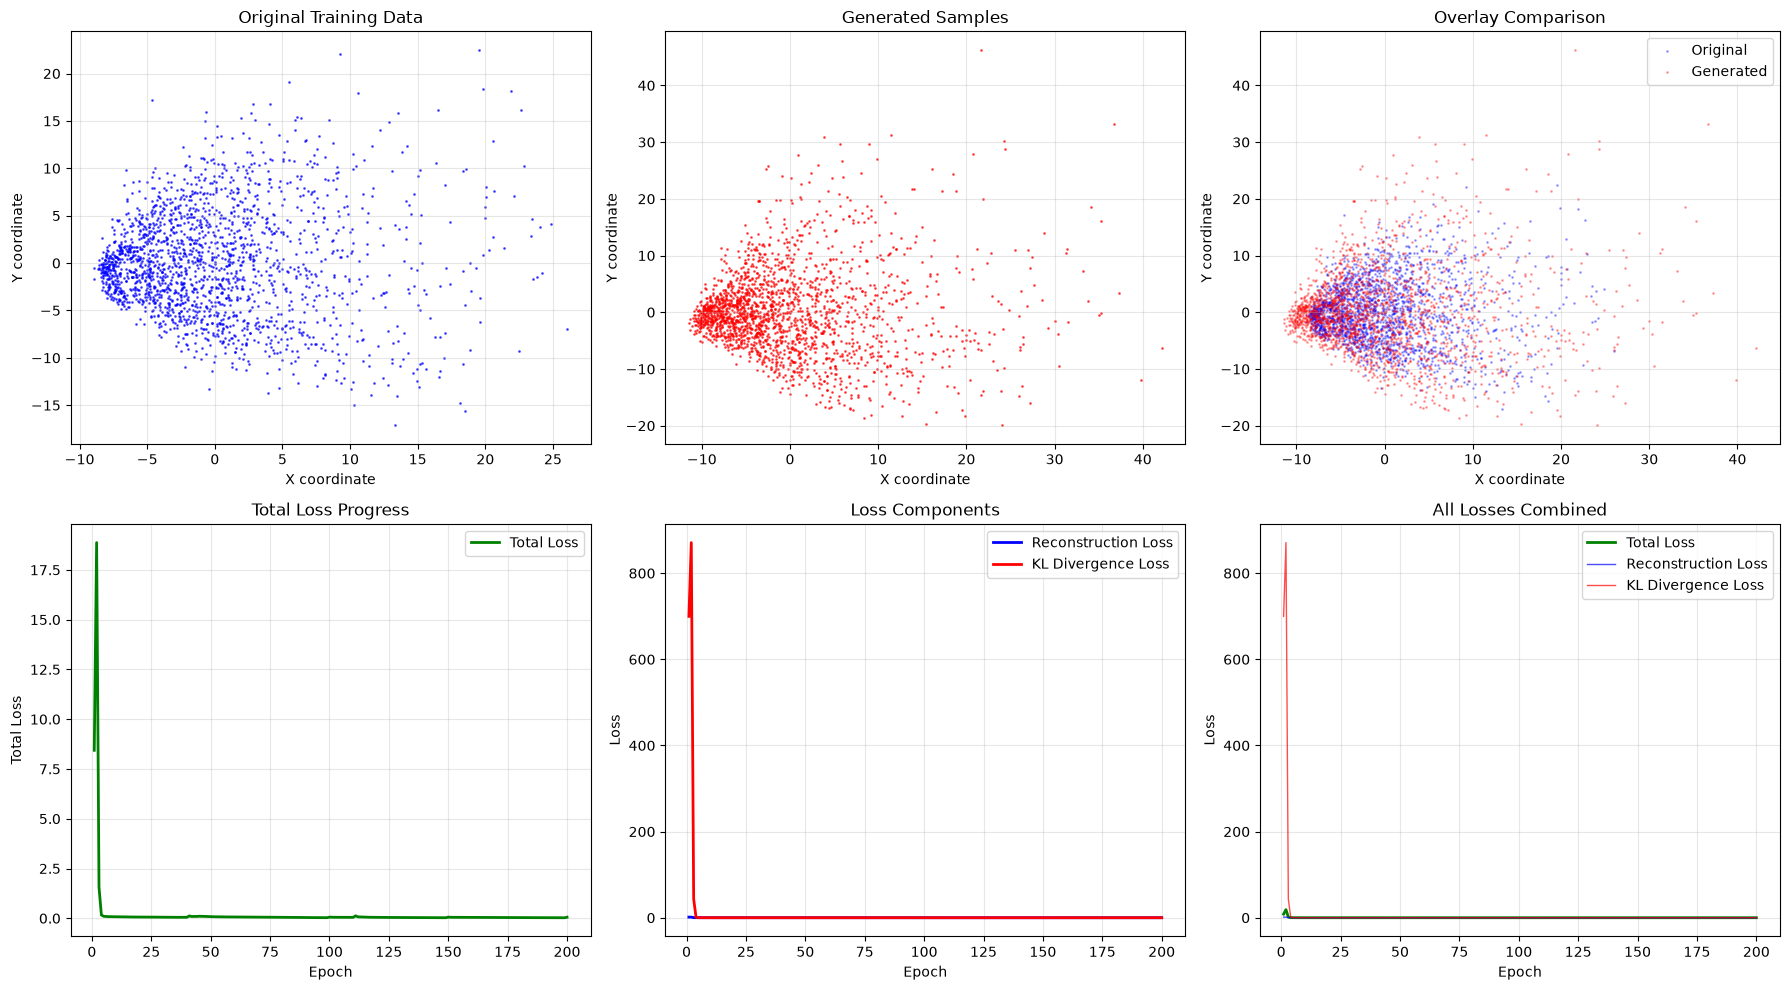

📈 Epoch 200 Summary:
   Total Loss: 0.0543
   Reconstruction Loss: 0.0278
   KL Divergence Loss: 0.0532
   Beta: 0.500
   Learning Rate: 0.000016

🎉 Training completed!
💾 Model saved as 'vae_model.pth'

🎨 Final comprehensive visualization:
💾 Saved plot: vae_results/vae_progress_epoch_200.png


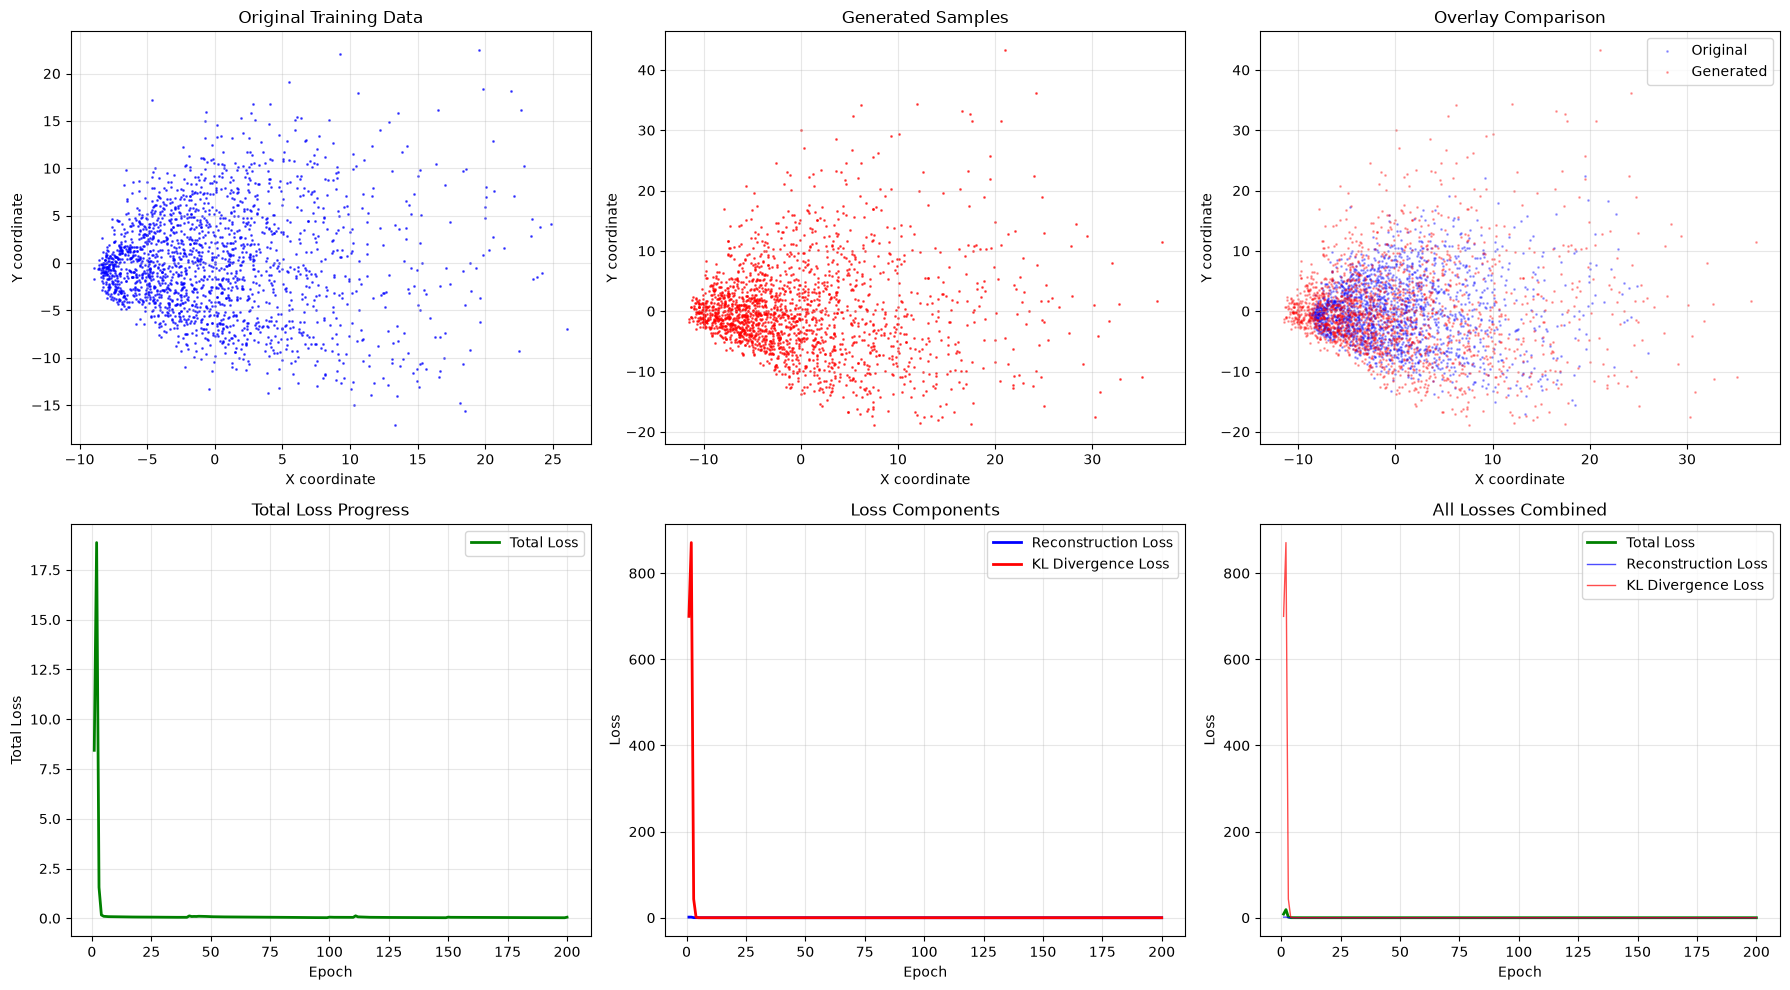

In [10]:
# Training loop
print("🎯 Starting VAE training...")
print("=" * 60)

# Lists to track training progress
total_losses = []
recon_losses = []
kl_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")
visualize_training_progress(0, [], [], [], save_plot=True)

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch
    avg_total_loss, avg_recon_loss, avg_kl_loss, current_beta = train_epoch(epoch)
    
    # Track losses
    total_losses.append(avg_total_loss)
    recon_losses.append(avg_recon_loss)
    kl_losses.append(avg_kl_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, total_losses, recon_losses, kl_losses, save_plot=True)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Total Loss: {avg_total_loss:.4f}")
    print(f"   Reconstruction Loss: {avg_recon_loss:.4f}")
    print(f"   KL Divergence Loss: {avg_kl_loss:.4f}")
    print(f"   Beta: {current_beta:.3f}")
    print(f"   Learning Rate: {optimizer.param_groups[0]['lr']:.6f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained model
torch.save(vae.state_dict(), 'models/vae_model.pth')
print("💾 Model saved as 'vae_model.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, total_losses, recon_losses, kl_losses, save_plot=True)


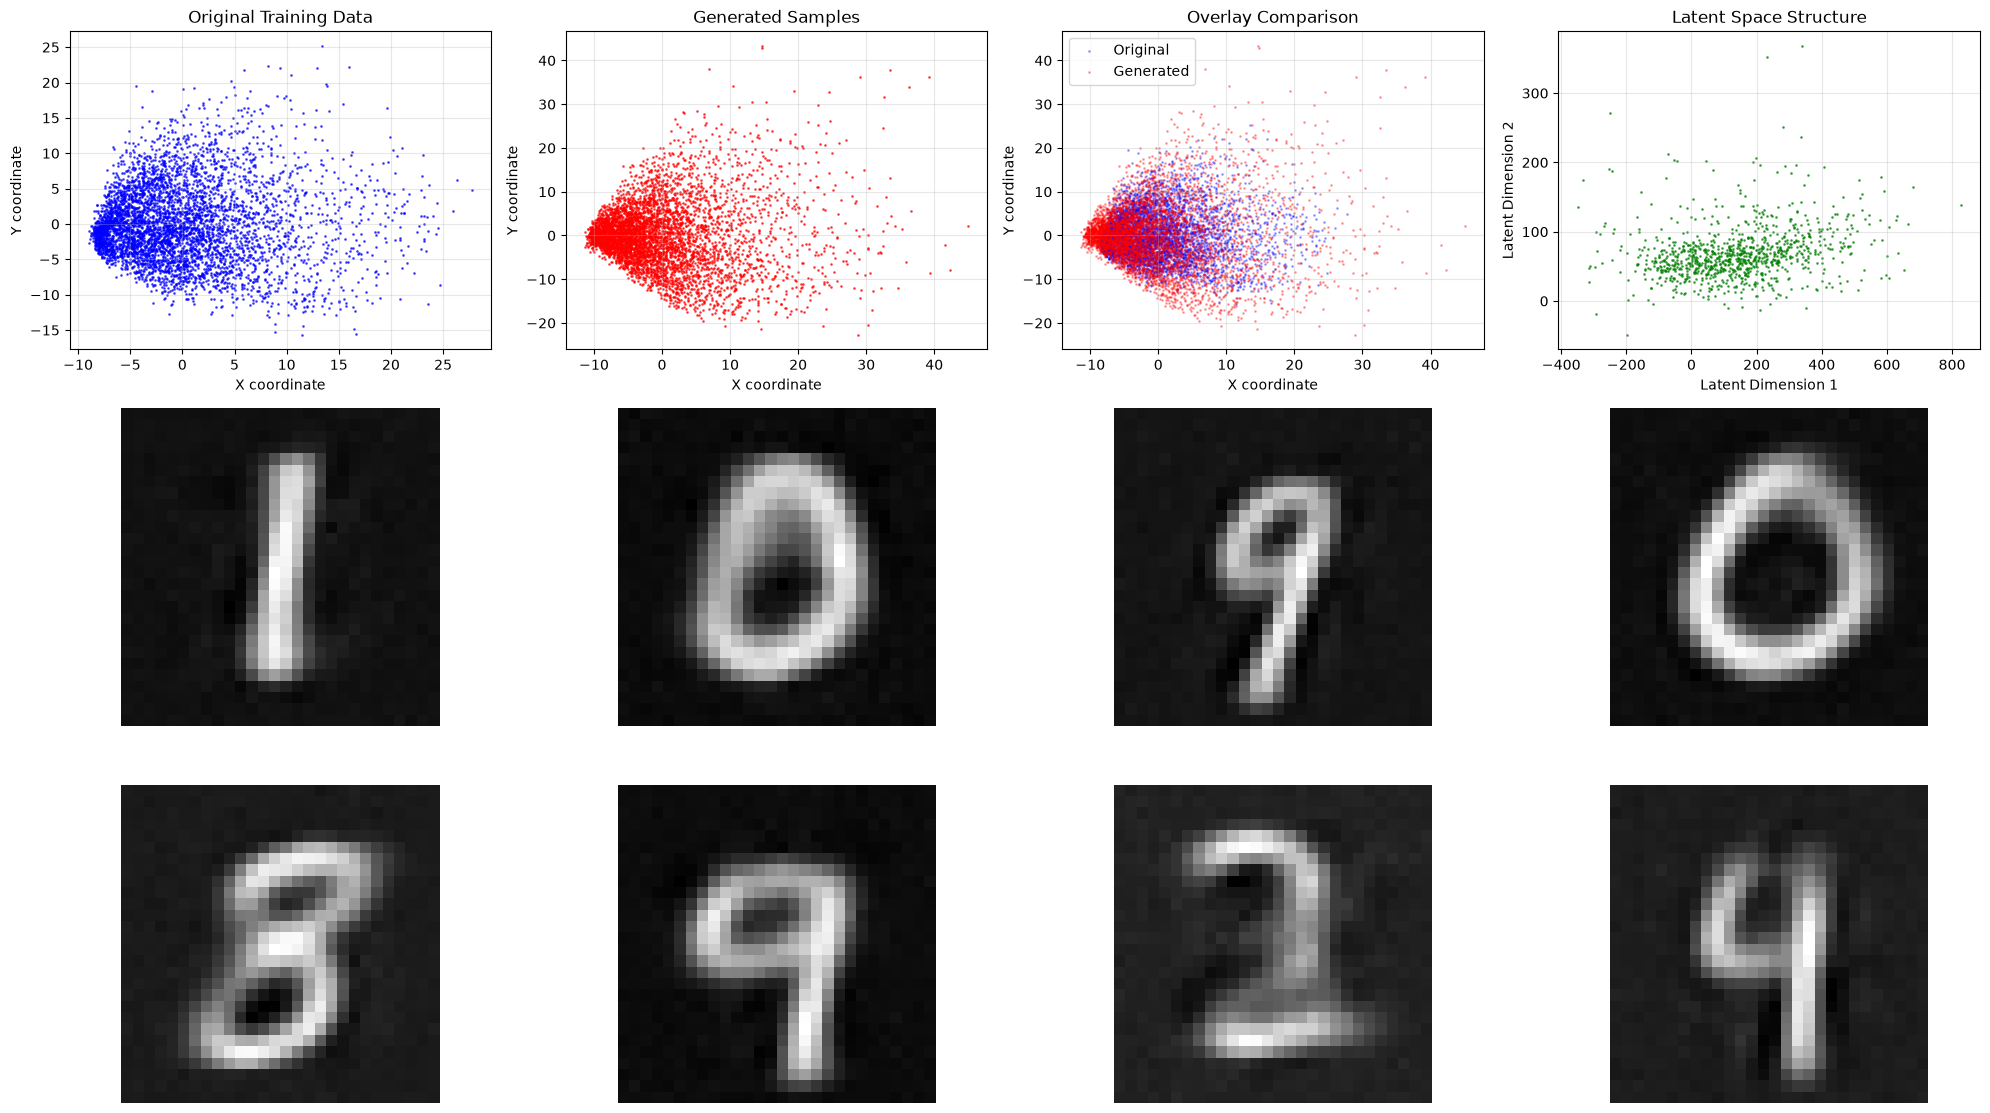

In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 4, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 4, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 4, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)

# Show the latent space structure
plt.subplot(4, 4, 4)
# Encode some real data to see latent space
vae.eval()
with torch.no_grad():
    train_data_reshaped = np.reshape(train_data.data[:1000], [1000, INPUT_DIM])
    mu, logvar = vae.encode(train_data_reshaped.to(device).float())
    latent_points = mu.cpu().numpy()

plt.scatter(latent_points[:, 0], latent_points[:, 1], c='green', s=1, alpha=0.6)
plt.title('Latent Space Structure')
plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.grid(True, alpha=0.3)


for i in range(8):
    plt.subplot(4, 4, 4 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


## 🚀 Next Steps and Experiments

Now that you understand the basics, here are some exciting experiments you can try:

### Easy Experiments:
1. **Change the Dataset**: Try different datasets like circles, spirals, or your own 2D data
2. **Adjust Hyperparameters**: 
   - Change learning rate (try 1e-4, 1e-2)
   - Modify network sizes (try 128, 512 hidden units)
   - Adjust beta parameter (try 0.1, 2.0, 10.0)
3. **Visualize Training**: Watch how the latent space evolves during training

### Intermediate Experiments:
4. **Different Latent Dimensions**: Try 1D, 3D, or 4D latent spaces
5. **Beta-VAE**: Experiment with different beta values to control disentanglement
6. **Conditional VAE**: Generate different types of data based on labels

### Advanced Experiments:
7. **Higher Dimensions**: Apply to image data (MNIST, CIFAR-10)
8. **WAE (Wasserstein Autoencoder)**: Implement the Wasserstein variant
9. **VAE-GAN**: Combine VAE with GAN for better generation quality

### Code Modifications to Try:
```python
# Try different datasets
from sklearn.datasets import make_circles, make_spiral
train_data = make_circles(n_samples=50000, noise=0.05)[0].astype(np.float32)

# Try different architectures
LATENT_DIM = 4         # Higher dimensional latent space
HIDDEN_DIM = 512       # Larger networks

# Try different beta values
BETA = 0.1             # Less regularization
BETA = 10.0            # More regularization
```


## 📚 Further Reading and Resources

### Papers to Read:
1. **Original VAE Paper**: "Auto-Encoding Variational Bayes" by Kingma & Welling (2014)
2. **Beta-VAE**: "β-VAE: Learning Basic Visual Concepts with a Constrained Variational Framework" by Higgins et al. (2017)
3. **WAE**: "Wasserstein Auto-Encoders" by Tolstikhin et al. (2018)
4. **VAE-GAN**: "Autoencoding beyond pixels using a learned similarity metric" by Larsen et al. (2016)

### Libraries to Explore:
- **PyTorch Lightning**: For easier VAE training
- **Hugging Face Transformers**: For text-based VAEs
- **Pyro**: Probabilistic programming with VAEs

### Applications:
- **Image Generation**: Creating new images from scratch
- **Data Compression**: Learning efficient representations
- **Anomaly Detection**: Finding unusual patterns in data
- **Data Augmentation**: Generating more training data
- **Representation Learning**: Learning useful features for downstream tasks

### Key Takeaways:
- VAEs are powerful tools for generative modeling and representation learning
- The reparameterization trick is crucial for training
- The beta parameter controls the trade-off between reconstruction and regularization
- VAEs provide a principled way to learn continuous latent representations
- The latent space can be used for interpolation and manipulation

### Common VAE Challenges:
- **Blurry Reconstructions**: VAEs tend to produce smoother, less sharp outputs
- **Posterior Collapse**: When the latent space becomes uninformative
- **Beta Tuning**: Finding the right balance between reconstruction and regularization
- **Evaluation**: Measuring VAE quality objectively

---

**Happy Learning! 🎓**

*Remember: The best way to learn is by experimenting. Try modifying the code, changing parameters, and seeing what happens. Every experiment teaches you something new about how VAEs work!*
